# Wet AMD Lesion Segmentation — Model 4: TransUNet (R50 + ViT-B/16) with Dual-Head Multi-Task Supervision

**Dataset:** AMD-SD (Optical Coherence Tomography Image Dataset for wet AMD Lesions Segmentation)

**Architecture Strategy (built on top of Model 1's dual-head pipeline):**
* **Hybrid CNN–Transformer Encoder (TransUNet, Chen et al. 2021):** A ResNet-50 (V2, GroupNorm + weight-standardised convs) stem extracts a feature pyramid ($512 \to 256 \to 128 \to 64 \to 32$ spatial resolution). The $1/16$-scale feature map ($32 \times 32$ tokens) is projected to 768-d and passed through a 12-layer ViT-B Transformer encoder, giving every token a **global receptive field** — a very different inductive bias from the purely convolutional U-Nets in Models 1–3.
* **Cascaded Upsampler Decoder with CNN Skips:** The transformer tokens are reshaped back to a $32 \times 32$ map and upsampled four times ($\times 2$ each). High-resolution skip connections come from the ResNet stages at $1/8$, $1/4$ and $1/2$ resolution, as in the original TransUNet.
* **Model 1's Dual-Head Design (kept for comparability):** An auxiliary binary lesion head predicts $\text{class} > 0$; its sigmoid probability is refined by a $7 \times 7$ convolution and concatenated with the decoder features before the multi-class head.
* **Pretrained vs. scratch switch:** `USE_PRETRAINED = True` initialises the R50+ViT-B/16 backbone from ImageNet-21k weights (via `timm` / Hugging Face Hub). `USE_PRETRAINED = False` trains the same architecture from random initialisation. Each setting writes its own checkpoint / logs so the two runs can be compared.
* **Identical training protocol to Models 1–3:** $512 \times 512$ inputs, flip + $\pm 10^\circ$ rotation, AdamW ($\eta = 10^{-4}$), `PolyLRScheduler`, gradient accumulation (effective batch 8), joint loss $\mathcal{L}_{\text{MC}} + 0.5 \cdot \mathcal{L}_{\text{BIN}}$, `GlobalMetricTracker`.


## 1. Setup and Reproducibility
Import dependencies, configure hardware acceleration (CUDA, MPS, or CPU), and set random seeds across Python, NumPy and PyTorch.

In [1]:
%pip install -q "timm>=0.9.12"

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import gc
import csv
import time
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, to_rgba
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset

try:
    import timm
except ImportError as e:
    raise ImportError("`timm` is required for the TransUNet backbone. Run the pip cell above (pip install timm).") from e

# Hardware & memory environment variables
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
os.environ["PYTORCH_MPS_HIGH_WATERMARK_RATIO"] = "0.0"

def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def cleanup_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    elif torch.backends.mps.is_available():
        torch.mps.empty_cache()

SEED = 42
seed_everything(SEED)
cleanup_memory()

device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Compute Device: {device} | torch {torch.__version__} | timm {timm.__version__}")

Active Compute Device: mps | torch 2.14.1 | timm 1.0.30


### 1.1 Run Configuration
All experiment switches live in this single cell.
* `USE_PRETRAINED` — ImageNet-21k initialisation for the R50+ViT-B/16 backbone (`True`) or random initialisation (`False`). Run the notebook once per setting to get the with/without comparison (checkpoints, logs and result files are tagged, so they never overwrite each other).
* `SMOKE_TEST` — runs 1 epoch of 20 training batches / 10 validation batches under a separate `_smoke` tag. **Do this first on your Mac** to confirm the whole pipeline runs end-to-end and to time a batch before committing to the full 20 epochs.
* `RUN_TRAINING` — set to `False` to skip training and only evaluate an already-saved checkpoint.

In [2]:
# ------------------------------- Experiment switches -------------------------------
USE_PRETRAINED = True    # True: R50+ViT-B/16 ImageNet-21k weights | False: random init (train from scratch)
SMOKE_TEST     = False   # True: 1 epoch x 20 train batches x 10 val batches (pipeline check only)
RUN_TRAINING   = True    # False: skip training, evaluate the existing checkpoint

# ------------------------------- Hyper-parameters (match Models 1-3) ---------------
EPOCHS            = 1 if SMOKE_TEST else 40
MAX_TRAIN_BATCHES = 20 if SMOKE_TEST else None
MAX_VAL_BATCHES   = 10 if SMOKE_TEST else None
LEARNING_RATE     = 1e-4
NUM_CLASSES       = 6
IMG_SIZE          = 512

# ------------------------------- File naming (tagged per experiment) --------------
TAG         = ("pretrained" if USE_PRETRAINED else "scratch") + ("_smoke" if SMOKE_TEST else "")
MODEL_KEY   = f"model4_{TAG}"
CKPT_PATH   = f"best_unet_{MODEL_KEY}.pth"
LOG_FILE    = f"{MODEL_KEY}_training_log.csv"
SAVE_PREFIX = MODEL_KEY

print(f"Experiment tag: {TAG}")
print(f"Checkpoint: {CKPT_PATH} | Training log: {LOG_FILE}")

Experiment tag: pretrained
Checkpoint: best_unet_model4_pretrained.pth | Training log: model4_pretrained_training_log.csv


## 2. Dataset Pipeline, Colour Palette & Target Generation
Loads pre-sliced OCT B-scans and categorical ground-truth masks from `processed_data/`, applies the same augmentations as Models 1–3, and returns synchronised multi-class and binary targets.

**Colour consistency (meeting note):** every figure in this notebook derives its class colours from the single `CLASS_PALETTE_RGB` table below — the colours used to *draw* the segmentation masks are exactly the colours used for the boxplots, confidence-interval plots and bar charts (SRF = red, IRF = green, PED = blue, SHRM = yellow, IS/OS = magenta).

In [3]:
CLASS_PALETTE_RGB = np.array([
    [0, 0, 0],        # 0: Background
    [255, 0, 0],      # 1: Subretinal Fluid (SRF)
    [0, 255, 0],      # 2: Intraretinal Fluid (IRF)
    [0, 0, 255],      # 3: Pigment Epithelial Detachment (PED)
    [255, 255, 0],    # 4: Subretinal Hyperreflective Material (SHRM)
    [255, 0, 255]     # 5: Ellipsoid Zone (IS/OS)
], dtype=np.int32)

CLASS_NAMES = ["Background", "SRF", "IRF", "PED", "SHRM", "IS/OS"]
LESION_NAMES = CLASS_NAMES[1:]

# ---- Single source of truth for colours (segmentation maps AND statistical plots) ----
CLASS_COLORS_HEX = {n: "#%02x%02x%02x" % tuple(int(v) for v in rgb) for n, rgb in zip(CLASS_NAMES, CLASS_PALETTE_RGB)}
PLOT_COLORS = {**CLASS_COLORS_HEX, "Mean": "#333333"}          # "Mean" summary column in plots
SEG_CMAP = ListedColormap(CLASS_PALETTE_RGB / 255.0)           # use with vmin=0, vmax=5

def seg_legend_handles(include_background=True):
    names = CLASS_NAMES if include_background else LESION_NAMES
    return [Patch(facecolor=CLASS_COLORS_HEX[n], edgecolor="black", label=n) for n in names]

def show_seg(ax, mask, title=None):
    ax.imshow(mask, cmap=SEG_CMAP, vmin=0, vmax=5, interpolation="nearest")
    if title:
        ax.set_title(title)
    ax.axis("off")


class AMDDatasetModel4(Dataset):
    def __init__(self, data_root="processed_data", split="train", target_size=(512, 512), augment=True):
        self.inputs_dir = os.path.join(data_root, split, "inputs")
        self.outputs_dir = os.path.join(data_root, split, "outputs")
        self.target_size = target_size
        self.split = split
        self.augment = augment and (split == "train")

        if not os.path.exists(self.inputs_dir):
            raise FileNotFoundError(f"Missing directory: {self.inputs_dir}. Please run dataset preprocessing first.")

        self.filenames = sorted([
            f for f in os.listdir(self.inputs_dir)
            if f.endswith(('.png', '.jpg', '.jpeg')) and not f.startswith('.')
        ])

    def __len__(self):
        return len(self.filenames)

    def _rgb_to_class(self, mask_rgb):
        mask = np.ascontiguousarray(mask_rgb, dtype=np.int32)
        dists = np.sum((mask[:, :, None, :] - CLASS_PALETTE_RGB[None, None, :, :]) ** 2, axis=-1)
        return np.argmin(dists, axis=-1)

    def _apply_augmentations(self, img, mask):
        if random.random() > 0.5:
            img = cv2.flip(img, 1)
            mask = cv2.flip(mask, 1)

        angle = random.uniform(-10.0, 10.0)
        h, w = img.shape[:2]
        center = (w // 2, h // 2)
        M = cv2.getRotationMatrix2D(center, angle, 1.0)
        img = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
        mask = cv2.warpAffine(mask, M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_REFLECT_101)
        return img, mask

    def __getitem__(self, idx):
        in_fname = self.filenames[idx]
        img_path = os.path.join(self.inputs_dir, in_fname)
        out_fname = in_fname.replace("_input", "_output") if "_input" in in_fname else in_fname
        mask_path = os.path.join(self.outputs_dir, out_fname)

        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        mask_bgr = cv2.imread(mask_path)
        if img is None or mask_bgr is None:
            raise ValueError(f"Corrupt pair at: {img_path}")

        mask_rgb = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (self.target_size[1], self.target_size[0]), interpolation=cv2.INTER_LINEAR)
        mask_rgb = cv2.resize(mask_rgb, (self.target_size[1], self.target_size[0]), interpolation=cv2.INTER_NEAREST)

        mask_labels = self._rgb_to_class(mask_rgb)

        if self.augment:
            img, mask_labels = self._apply_augmentations(img, mask_labels)

        img_tensor = torch.from_numpy(np.ascontiguousarray(img)).unsqueeze(0).float() / 255.0
        mask_tensor = torch.from_numpy(np.ascontiguousarray(mask_labels)).long()
        bin_tensor = (mask_tensor > 0).float().unsqueeze(0)

        return img_tensor, mask_tensor, bin_tensor


DATA_DIR = "processed_data"
MICRO_BATCH_SIZE = 2 if device.type == "mps" else 8
ACCUM_STEPS = 4 if device.type == "mps" else 1
VAL_BATCH_SIZE = 2 if device.type == "mps" else 8
NUM_WORKERS = 0 if device.type == "mps" else 4

train_dataset = AMDDatasetModel4(DATA_DIR, split="train", target_size=(IMG_SIZE, IMG_SIZE), augment=True)
val_dataset = AMDDatasetModel4(DATA_DIR, split="val", target_size=(IMG_SIZE, IMG_SIZE), augment=False)

train_loader = DataLoader(train_dataset, batch_size=MICRO_BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
val_loader = DataLoader(val_dataset, batch_size=VAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

print(f"Loaded {len(train_dataset)} train samples and {len(val_dataset)} validation samples.")
print(f"Physical micro-batch: {MICRO_BATCH_SIZE} | accumulation steps: {ACCUM_STEPS} | effective batch: {MICRO_BATCH_SIZE * ACCUM_STEPS}")

Loaded 2346 train samples and 703 validation samples.
Physical micro-batch: 2 | accumulation steps: 4 | effective batch: 8


## 3. Model 4 Architecture Definition: TransUNet Dual-Head

**Encoder (hybrid R50 + ViT-B/16, from `timm`'s `vit_base_r50_s16_224`):**
1. Grayscale OCT is replicated to 3 channels and normalised to $[-1, 1]$ (the input convention of the original ViT weights).
2. ResNet-50 stages produce skip features at $1/2$ (64 ch), $1/4$ (256 ch), $1/8$ (512 ch), and the bottleneck map at $1/16$ (1024 ch).
3. A $1 \times 1$ projection maps the $1/16$ map to 768-d tokens ($32 \times 32 = 1024$ tokens at $512 \times 512$ input); learned position embeddings (bicubically resampled from $14 \times 14$ to $32 \times 32$ when pretrained) are added and 12 Transformer blocks are applied. The `[CLS]` token is dropped, as in TransUNet.

**Decoder (cascaded upsampler):** `conv_more` ($768 \to 512$) followed by four $\times 2$ bilinear-upsample blocks with channels $256 \to 128 \to 64 \to 16$; the first three blocks concatenate the ResNet skips at $1/8$, $1/4$, $1/2$. Output: 16 channels at full $512 \times 512$ resolution.

**Heads (identical logic to Model 1):** `binary_head` ($1 \times 1$ conv) $\to$ sigmoid $\to$ $7 \times 7$ refinement conv $\to$ concatenated with decoder features $\to$ `DoubleConv` + $1 \times 1$ conv multi-class head.

*Returns* `(mc_logits, bin_logits)` — the same interface as Models 1 and 3.

In [4]:
class DoubleConv(nn.Module):
    """[Conv2d -> BatchNorm -> ReLU] * 2"""
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)


class Conv2dReLU(nn.Sequential):
    def __init__(self, in_channels: int, out_channels: int, kernel_size: int = 3, padding: int = 1):
        super().__init__(
            nn.Conv2d(in_channels, out_channels, kernel_size, padding=padding, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )


class DecoderBlock(nn.Module):
    """x2 bilinear upsample -> (optional) concat CNN skip -> 2 x [Conv3x3 -> BN -> ReLU]."""
    def __init__(self, in_channels: int, skip_channels: int, out_channels: int):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.conv1 = Conv2dReLU(in_channels + skip_channels, out_channels)
        self.conv2 = Conv2dReLU(out_channels, out_channels)

    def forward(self, x: torch.Tensor, skip: torch.Tensor = None) -> torch.Tensor:
        x = self.up(x)
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        return self.conv2(self.conv1(x))


class TransUNetEncoder(nn.Module):
    """
    Hybrid ResNet-50 + ViT-B/16 encoder (TransUNet). Wraps timm's `vit_base_r50_s16_224`:
      - backbone (ResNetV2): stem (/2, 64ch) -> stage0 (/4, 256ch) -> stage1 (/8, 512ch) -> stage2 (/16, 1024ch)
      - patch_embed.proj: 1x1 conv 1024 -> 768
      - 12 Transformer blocks over (H/16 * W/16) tokens
    """
    SKIP_CHANNELS = (512, 256, 64)   # skips at 1/8, 1/4, 1/2 (decoder order)

    def __init__(self, img_size: int = 512, pretrained: bool = True):
        super().__init__()
        assert img_size % 16 == 0, "img_size must be divisible by 16"
        self.img_size = img_size
        self.vit = self._build_vit(img_size, pretrained)
        self.backbone = self.vit.patch_embed.backbone   # ResNetV2 (stem + 3 stages)
        self.proj = self.vit.patch_embed.proj           # 1x1 conv: 1024 -> 768
        self.hidden_dim = self.vit.embed_dim

    @staticmethod
    def _build_vit(img_size: int, pretrained: bool):
        names = ["vit_base_r50_s16_224.orig_in21k", "vit_base_r50_s16_224_in21k"] if pretrained else ["vit_base_r50_s16_224"]
        last_err = None
        for name in names:
            try:
                # img_size=512 -> timm resamples the pretrained 14x14 position embeddings to 32x32
                return timm.create_model(name, pretrained=pretrained, num_classes=0, img_size=img_size)
            except Exception as e:  # unknown name (older timm) or weight download failure
                print(f"[TransUNetEncoder] timm.create_model('{name}', pretrained={pretrained}) failed: {e}")
                last_err = e
        raise RuntimeError(
            "Could not build the R50+ViT-B/16 backbone. If pretrained=True, check your internet connection "
            "(weights are fetched from the Hugging Face Hub on first use) or upgrade timm (pip install -U timm), "
            "or set USE_PRETRAINED = False."
        ) from last_err

    def forward(self, x: torch.Tensor):
        if x.shape[-2:] != (self.img_size, self.img_size):
            raise ValueError(f"Expected {self.img_size}x{self.img_size} input, got {tuple(x.shape[-2:])}.")
        if x.shape[1] == 1:
            x = x.repeat(1, 3, 1, 1)          # grayscale -> 3 channels
        x = (x - 0.5) / 0.5                   # [0,1] -> [-1,1] (ViT-R50 in21k input convention)

        bb = self.backbone
        s0 = bb.stem.norm(bb.stem.conv(x))    # 1/2  : 64 ch
        h = bb.stem.pool(s0)                  # 1/4
        s1 = bb.stages[0](h)                  # 1/4  : 256 ch
        s2 = bb.stages[1](s1)                 # 1/8  : 512 ch
        f = bb.stages[2](s2)                  # 1/16 : 1024 ch
        f = bb.norm(f)                        # Identity for this backbone

        t = self.proj(f)                      # (B, 768, H/16, W/16)
        B, C, Hp, Wp = t.shape
        t = t.flatten(2).transpose(1, 2)      # (B, N, 768)
        t = self.vit._pos_embed(t)            # + [CLS] + position embeddings
        if hasattr(self.vit, "patch_drop"):
            t = self.vit.patch_drop(t)
        if hasattr(self.vit, "norm_pre"):
            t = self.vit.norm_pre(t)
        t = self.vit.blocks(t)
        t = self.vit.norm(t)
        t = t[:, self.vit.num_prefix_tokens:]                 # drop [CLS]
        t = t.transpose(1, 2).reshape(B, C, Hp, Wp)           # tokens -> feature map
        return t, [s2, s1, s0]                                # skips ordered 1/8, 1/4, 1/2


class TransUNetDecoder(nn.Module):
    def __init__(self, hidden_dim: int = 768, head_channels: int = 512,
                 decoder_channels=(256, 128, 64, 16), skip_channels=(512, 256, 64, 0)):
        super().__init__()
        self.conv_more = Conv2dReLU(hidden_dim, head_channels)
        in_channels = [head_channels] + list(decoder_channels[:-1])
        self.blocks = nn.ModuleList([
            DecoderBlock(i, s, o) for i, s, o in zip(in_channels, skip_channels, decoder_channels)
        ])

    def forward(self, tokens_map: torch.Tensor, skips) -> torch.Tensor:
        x = self.conv_more(tokens_map)
        for i, block in enumerate(self.blocks):
            x = block(x, skips[i] if i < len(skips) else None)
        return x


class TransUNetDualHead(nn.Module):
    """Model 4: TransUNet encoder-decoder + Model 1's auxiliary binary head / 7x7 guidance / multi-class head."""
    def __init__(self, in_channels: int = 1, num_classes: int = 6, img_size: int = 512, pretrained: bool = True,
                 decoder_channels=(256, 128, 64, 16)):
        super().__init__()
        assert in_channels == 1, "Grayscale OCT input is replicated to 3 channels inside the encoder."
        self.encoder = TransUNetEncoder(img_size=img_size, pretrained=pretrained)
        self.decoder = TransUNetDecoder(
            hidden_dim=self.encoder.hidden_dim,
            decoder_channels=decoder_channels,
            skip_channels=tuple(TransUNetEncoder.SKIP_CHANNELS) + (0,),
        )
        c = decoder_channels[-1]

        # Head 1: auxiliary binary lesion head
        self.binary_head = nn.Conv2d(c, 1, kernel_size=1)

        # 7x7 refinement block on the binary probability map (as in Model 1)
        self.refine_kernel7 = nn.Sequential(
            nn.Conv2d(1, c, kernel_size=7, padding=3, bias=False),
            nn.BatchNorm2d(c),
            nn.ReLU(inplace=True)
        )

        # Head 2: multi-class head
        self.multiclass_head = nn.Sequential(
            DoubleConv(c * 2, c),
            nn.Conv2d(c, num_classes, kernel_size=1)
        )

    def forward(self, x: torch.Tensor):
        tokens_map, skips = self.encoder(x)
        dec_features = self.decoder(tokens_map, skips)             # (B, 16, H, W)

        binary_logits = self.binary_head(dec_features)
        guidance = self.refine_kernel7(torch.sigmoid(binary_logits))
        fused = torch.cat([dec_features, guidance], dim=1)
        mc_logits = self.multiclass_head(fused)
        return mc_logits, binary_logits


def load_model4(ckpt_path: str):
    """Rebuild Model 4 (no pretrained download needed) and load a trained checkpoint for evaluation."""
    if not os.path.exists(ckpt_path):
        raise FileNotFoundError(f"Checkpoint not found at '{ckpt_path}'. Train the model first.")
    net = TransUNetDualHead(in_channels=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE, pretrained=False).to(device)
    net.load_state_dict(torch.load(ckpt_path, map_location=device))
    net.eval()
    return net

### 3.1 Architecture Sanity Check
Forward-pass shape verification, encoder feature-pyramid inspection, and parameter breakdown. If `USE_PRETRAINED = True` this cell also triggers the (one-off) weight download, so any connection problem shows up here rather than at the start of training.

In [5]:
test_net = TransUNetDualHead(in_channels=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE, pretrained=USE_PRETRAINED).to(device)
test_net.eval()
dummy_in = torch.randn(2, 1, IMG_SIZE, IMG_SIZE, device=device)

with torch.no_grad():
    tokens_map, skips = test_net.encoder(dummy_in)
    test_mc, test_bin = test_net(dummy_in)

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

print(f"Pretrained backbone:             {USE_PRETRAINED}")
print(f"Position-embedding shape:        {tuple(test_net.encoder.vit.pos_embed.shape)}  (expected (1, 1025, 768) = [CLS] + 32x32 tokens)")
print(f"Transformer token map:           {tuple(tokens_map.shape)}")
print(f"CNN skips (1/8, 1/4, 1/2):       {[tuple(s.shape) for s in skips]}")
print(f"Multi-class logits:              {tuple(test_mc.shape)}")
print(f"Binary logits:                   {tuple(test_bin.shape)}")
print(f"Encoder (R50 + ViT-B) params:    {count_params(test_net.encoder):,}")
print(f"Decoder params:                  {count_params(test_net.decoder):,}")
print(f"Total trainable parameters:      {count_params(test_net):,}")

assert tokens_map.shape == (2, 768, IMG_SIZE // 16, IMG_SIZE // 16)
assert [s.shape[1] for s in skips] == [512, 256, 64]
assert test_mc.shape == (2, NUM_CLASSES, IMG_SIZE, IMG_SIZE) and test_bin.shape == (2, 1, IMG_SIZE, IMG_SIZE)
print("\nTransUNetDualHead architecture successfully verified!")

del test_net, dummy_in, tokens_map, skips, test_mc, test_bin
cleanup_memory()

Pretrained backbone:             True
Position-embedding shape:        (1, 1025, 768)  (expected (1, 1025, 768) = [CLS] + 32x32 tokens)
Transformer token map:           (2, 768, 32, 32)
CNN skips (1/8, 1/4, 1/2):       [(2, 512, 64, 64), (2, 256, 128, 128), (2, 64, 256, 256)]
Multi-class logits:              (2, 6, 512, 512)
Binary logits:                   (2, 1, 512, 512)
Encoder (R50 + ViT-B) params:    98,526,016
Decoder params:                  7,387,200
Total trainable parameters:      105,921,127

TransUNetDualHead architecture successfully verified!


## 4. Multi-Task Objective, Global Metric Accumulation, and Learning Rate Schedule
Identical to Models 1 and 3, so results are directly comparable: multi-task loss $\mathcal{L}_{\text{MC}} + 0.5 \cdot \mathcal{L}_{\text{BIN}}$ (CE + soft Dice on classes 1–5, BCE + binary Dice), `GlobalMetricTracker` (pixel-pooled Dice / IoU over the whole split, as in the AMD-SD benchmark protocol), and the polynomial LR scheduler.

In [6]:
class MultiTaskLoss(nn.Module):
    def __init__(self, num_classes: int = 6, ignore_index: int = 255, binary_weight: float = 0.5,
                 ce_weight: float = 0.5, dice_weight: float = 0.5, smooth: float = 1.0):
        super().__init__()
        self.num_classes = num_classes
        self.ignore_index = ignore_index
        self.binary_weight = binary_weight
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight
        self.smooth = smooth
        self.ce = nn.CrossEntropyLoss(ignore_index=ignore_index)

    def forward(self, mc_logits: torch.Tensor, bin_logits: torch.Tensor,
                targets: torch.Tensor, bin_targets: torch.Tensor):
        # 1. Multi-Class Loss
        ce_loss = self.ce(mc_logits, targets)
        probs = F.softmax(mc_logits, dim=1)
        valid_mask = (targets != self.ignore_index)

        targets_clean = targets.clone()
        targets_clean[~valid_mask] = 0
        targets_one_hot = F.one_hot(targets_clean, num_classes=self.num_classes).permute(0, 3, 1, 2).float()

        dice_total = 0.0
        for c in range(1, self.num_classes):
            p = probs[:, c, ...][valid_mask]
            t = targets_one_hot[:, c, ...][valid_mask]
            intersection = (p * t).sum()
            dice = (2.0 * intersection + self.smooth) / (p.sum() + t.sum() + self.smooth)
            dice_total += (1.0 - dice)

        mc_dice_loss = dice_total / (self.num_classes - 1)
        l_mc = (self.ce_weight * ce_loss) + (self.dice_weight * mc_dice_loss)

        # 2. Binary Detection Loss
        valid_mask_bin = valid_mask.unsqueeze(1)
        b_logits_valid = bin_logits[valid_mask_bin]
        b_targets_valid = bin_targets[valid_mask_bin]

        bce_loss = F.binary_cross_entropy_with_logits(b_logits_valid, b_targets_valid)
        b_probs = torch.sigmoid(b_logits_valid)
        b_intersection = (b_probs * b_targets_valid).sum()
        b_dice = (2.0 * b_intersection + self.smooth) / (b_probs.sum() + b_targets_valid.sum() + self.smooth)
        b_dice_loss = 1.0 - b_dice

        l_bin = (0.5 * bce_loss) + (0.5 * b_dice_loss)

        total_loss = l_mc + (self.binary_weight * l_bin)
        return total_loss, l_mc, l_bin


class GlobalMetricTracker:
    """Pixel-pooled Dice / IoU over a whole split (matches the AMD-SD Table 3 protocol)."""
    def __init__(self, num_classes: int = 6):
        self.num_classes = num_classes
        self.class_map = {1: "SRF", 2: "IRF", 3: "PED", 4: "SHRM", 5: "IS/OS"}
        self.reset()

    def reset(self):
        self.intersections = {c: 0.0 for c in range(1, self.num_classes)}
        self.total_preds = {c: 0.0 for c in range(1, self.num_classes)}
        self.total_targets = {c: 0.0 for c in range(1, self.num_classes)}

    def update(self, preds: torch.Tensor, targets: torch.Tensor):
        for c in range(1, self.num_classes):
            p = (preds == c).float()
            t = (targets == c).float()
            self.intersections[c] += (p * t).sum().item()
            self.total_preds[c] += p.sum().item()
            self.total_targets[c] += t.sum().item()

    def compute(self):
        dice_scores, iou_scores = {}, {}
        for c, name in self.class_map.items():
            inter = self.intersections[c]
            p_sum = self.total_preds[c]
            t_sum = self.total_targets[c]
            union = p_sum + t_sum - inter

            dice = (2.0 * inter) / (p_sum + t_sum + 1e-8) * 100.0
            iou = inter / (union + 1e-8) * 100.0
            dice_scores[name] = dice
            iou_scores[name] = iou

        mean_dice = sum(dice_scores.values()) / len(dice_scores)
        mean_iou = sum(iou_scores.values()) / len(iou_scores)
        return dice_scores, iou_scores, mean_dice, mean_iou


class PolyLRScheduler(torch.optim.lr_scheduler._LRScheduler):
    def __init__(self, optimizer, max_epochs, power=0.9, min_lr=1e-6, last_epoch=-1):
        self.max_epochs = max_epochs
        self.power = power
        self.min_lr = min_lr
        super().__init__(optimizer, last_epoch)

    def get_lr(self):
        factor = (1.0 - self.last_epoch / max(1, self.max_epochs)) ** self.power
        return [max(self.min_lr, base_lr * factor) for base_lr in self.base_lrs]

## 5. Supervised Training Loop & Checkpointing
Trains Model 4 with AdamW ($\eta = 10^{-4}$, weight decay $10^{-4}$), gradient accumulation, and `PolyLRScheduler`. The best-validation-Mean-Dice weights are saved to `best_unet_model4_<tag>.pth`, per-epoch metrics go to `model4_<tag>_training_log.csv`, and a line is appended to `checkpoints.txt` (as in Model 1).

> **Heads-up:** a 105M-parameter R50+ViT-B at $512 \times 512$ is substantially heavier than Models 1–3. Run the `SMOKE_TEST = True` configuration first to time a batch on your Mac. You can interrupt training safely: the best checkpoint so far is already on disk.

In [7]:
def run_model4_training():
    cleanup_memory()
    seed_everything(SEED)

    model = TransUNetDualHead(in_channels=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE, pretrained=USE_PRETRAINED).to(device)
    criterion = MultiTaskLoss(num_classes=NUM_CLASSES, ignore_index=255, binary_weight=0.5,
                              ce_weight=0.5, dice_weight=0.5, smooth=1.0).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    scheduler = PolyLRScheduler(optimizer, max_epochs=EPOCHS, power=0.9, min_lr=1e-6)

    n_train_steps = len(train_loader) if MAX_TRAIN_BATCHES is None else min(len(train_loader), MAX_TRAIN_BATCHES)
    n_val_steps = len(val_loader) if MAX_VAL_BATCHES is None else min(len(val_loader), MAX_VAL_BATCHES)

    fieldnames = [
        "epoch", "train_loss", "val_loss", "mean_dice", "mean_iou",
        "SRF_dice", "IRF_dice", "PED_dice", "SHRM_dice", "IS_OS_dice",
        "SRF_iou", "IRF_iou", "PED_iou", "SHRM_iou", "IS_OS_iou"
    ]
    with open(LOG_FILE, "w", newline="") as f:
        csv.DictWriter(f, fieldnames=fieldnames).writeheader()

    best_mean_dice = 0.0
    print(f"Beginning Model 4 Training (TransUNet dual-head | pretrained={USE_PRETRAINED} | tag={TAG})...")
    print(f"{n_train_steps} train steps/epoch, {n_val_steps} val steps/epoch, {EPOCHS} epoch(s).")

    for epoch in range(1, EPOCHS + 1):
        t_epoch = time.time()
        model.train()
        train_loss_accum = 0.0
        optimizer.zero_grad(set_to_none=True)

        pbar = tqdm(train_loader, total=n_train_steps, desc=f"Epoch {epoch:02d}/{EPOCHS} [Train]")
        for step, (images, mc_targets, bin_targets) in enumerate(pbar):
            if step >= n_train_steps:
                break
            images = images.to(device)
            mc_targets = mc_targets.to(device, dtype=torch.long)
            bin_targets = bin_targets.to(device, dtype=torch.float32)

            mc_logits, bin_logits = model(images)
            loss, l_mc, l_bin = criterion(mc_logits, bin_logits, mc_targets, bin_targets)

            (loss / ACCUM_STEPS).backward()

            if (step + 1) % ACCUM_STEPS == 0 or (step + 1) == n_train_steps:
                optimizer.step()
                optimizer.zero_grad(set_to_none=True)

            train_loss_accum += loss.item()
            pbar.set_postfix({"tot": f"{loss.item():.4f}", "mc": f"{l_mc.item():.3f}", "bin": f"{l_bin.item():.3f}"})

        scheduler.step()
        epoch_train_loss = train_loss_accum / n_train_steps

        # Validation Phase
        model.eval()
        val_loss_accum = 0.0
        metric_tracker = GlobalMetricTracker(num_classes=NUM_CLASSES)

        with torch.no_grad():
            vbar = tqdm(val_loader, total=n_val_steps, desc=f"Epoch {epoch:02d}/{EPOCHS} [Val]")
            for vstep, (images, mc_targets, bin_targets) in enumerate(vbar):
                if vstep >= n_val_steps:
                    break
                images = images.to(device)
                mc_targets = mc_targets.to(device, dtype=torch.long)
                bin_targets = bin_targets.to(device, dtype=torch.float32)

                mc_logits, bin_logits = model(images)
                loss, _, _ = criterion(mc_logits, bin_logits, mc_targets, bin_targets)
                val_loss_accum += loss.item()

                preds = torch.argmax(mc_logits, dim=1)
                metric_tracker.update(preds, mc_targets)

        epoch_val_loss = val_loss_accum / n_val_steps
        avg_dice, avg_iou, mean_dice, mean_iou = metric_tracker.compute()

        print(f"\n--- Epoch {epoch:02d} Summary (Model 4 | {TAG}) --- [{(time.time() - t_epoch) / 60:.1f} min]")
        print(f"Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")
        print(f"Mean Dice:  {mean_dice:.2f}% | Mean IoU: {mean_iou:.2f}%")
        print(f"Per-Class Dice -> SRF: {avg_dice['SRF']:.2f}% | IRF: {avg_dice['IRF']:.2f}% | "
              f"PED: {avg_dice['PED']:.2f}% | SHRM: {avg_dice['SHRM']:.2f}% | IS/OS: {avg_dice['IS/OS']:.2f}%")

        log_entry = {
            "epoch": epoch,
            "train_loss": f"{epoch_train_loss:.4f}",
            "val_loss": f"{epoch_val_loss:.4f}",
            "mean_dice": f"{mean_dice:.2f}",
            "mean_iou": f"{mean_iou:.2f}",
            "SRF_dice": f"{avg_dice['SRF']:.2f}",
            "IRF_dice": f"{avg_dice['IRF']:.2f}",
            "PED_dice": f"{avg_dice['PED']:.2f}",
            "SHRM_dice": f"{avg_dice['SHRM']:.2f}",
            "IS_OS_dice": f"{avg_dice['IS/OS']:.2f}",
            "SRF_iou": f"{avg_iou['SRF']:.2f}",
            "IRF_iou": f"{avg_iou['IRF']:.2f}",
            "PED_iou": f"{avg_iou['PED']:.2f}",
            "SHRM_iou": f"{avg_iou['SHRM']:.2f}",
            "IS_OS_iou": f"{avg_iou['IS/OS']:.2f}"
        }
        with open(LOG_FILE, "a", newline="") as f:
            csv.DictWriter(f, fieldnames=fieldnames).writerow(log_entry)

        if mean_dice > best_mean_dice:
            best_mean_dice = mean_dice
            torch.save(model.state_dict(), CKPT_PATH)
            with open("checkpoints.txt", "a") as f_ckpt:
                f_ckpt.write(f"Model4-{TAG} | Epoch {epoch:02d} | Val Mean Dice: {best_mean_dice:.2f}% | Path: {CKPT_PATH}\n")
            print(f"--> Saved optimal Model 4 checkpoint with Mean Dice: {best_mean_dice:.2f}%")

        cleanup_memory()

    print(f"\nModel 4 Training Complete. Peak Validation Mean Dice: {best_mean_dice:.2f}%")


if RUN_TRAINING:
    run_model4_training()
else:
    print(f"RUN_TRAINING = False -> skipping training. Using existing checkpoint '{CKPT_PATH}'.")

Beginning Model 4 Training (TransUNet dual-head | pretrained=True | tag=pretrained)...
1173 train steps/epoch, 352 val steps/epoch, 40 epoch(s).


Epoch 01/40 [Val]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 352/352 [02:16<00:00,  2.57it/s]



--- Epoch 01 Summary (Model 4 | pretrained) --- [27.5 min]
Train Loss: 1.4604 | Val Loss: 1.3380
Mean Dice:  56.10% | Mean IoU: 42.64%
Per-Class Dice -> SRF: 60.17% | IRF: 7.22% | PED: 65.25% | SHRM: 67.86% | IS/OS: 80.00%
--> Saved optimal Model 4 checkpoint with Mean Dice: 56.10%


Epoch 02/40 [Val]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 352/352 [02:18<00:00,  2.55it/s]



--- Epoch 02 Summary (Model 4 | pretrained) --- [26.8 min]
Train Loss: 1.2494 | Val Loss: 1.1695
Mean Dice:  75.45% | Mean IoU: 60.69%
Per-Class Dice -> SRF: 76.23% | IRF: 75.50% | PED: 73.68% | SHRM: 70.80% | IS/OS: 81.03%
--> Saved optimal Model 4 checkpoint with Mean Dice: 75.45%


...


--- Epoch 38 Summary (Model 4 | pretrained) --- [27.3 min]
Train Loss: 0.1864 | Val Loss: 0.3672
Mean Dice:  80.21% | Mean IoU: 67.15%
Per-Class Dice -> SRF: 80.57% | IRF: 82.35% | PED: 82.64% | SHRM: 72.07% | IS/OS: 83.40%


Epoch 39/40 [Val]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 352/352 [02:14<00:00,  2.61it/s]



--- Epoch 39 Summary (Model 4 | pretrained) --- [26.6 min]
Train Loss: 0.1812 | Val Loss: 0.3667
Mean Dice:  80.04% | Mean IoU: 66.92%
Per-Class Dice -> SRF: 80.32% | IRF: 82.19% | PED: 82.55% | SHRM: 71.78% | IS/OS: 83.37%


Epoch 40/40 [Val]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 352/352 [02:17<00:00,  2.56it/s]



--- Epoch 40 Summary (Model 4 | pretrained) --- [26.8 min]
Train Loss: 0.1791 | Val Loss: 0.3661
Mean Dice:  80.01% | Mean IoU: 66.88%
Per-Class Dice -> SRF: 80.42% | IRF: 82.16% | PED: 82.42% | SHRM: 71.72% | IS/OS: 83.34%

Model 4 Training Complete. Peak Validation Mean Dice: 80.54%


## 6. Training Metric Trajectory
Plots the loss curves, validation Mean Dice / IoU, and per-biomarker Dice trajectories from the training log. Per-biomarker curves use the same class colours as the segmentation masks.

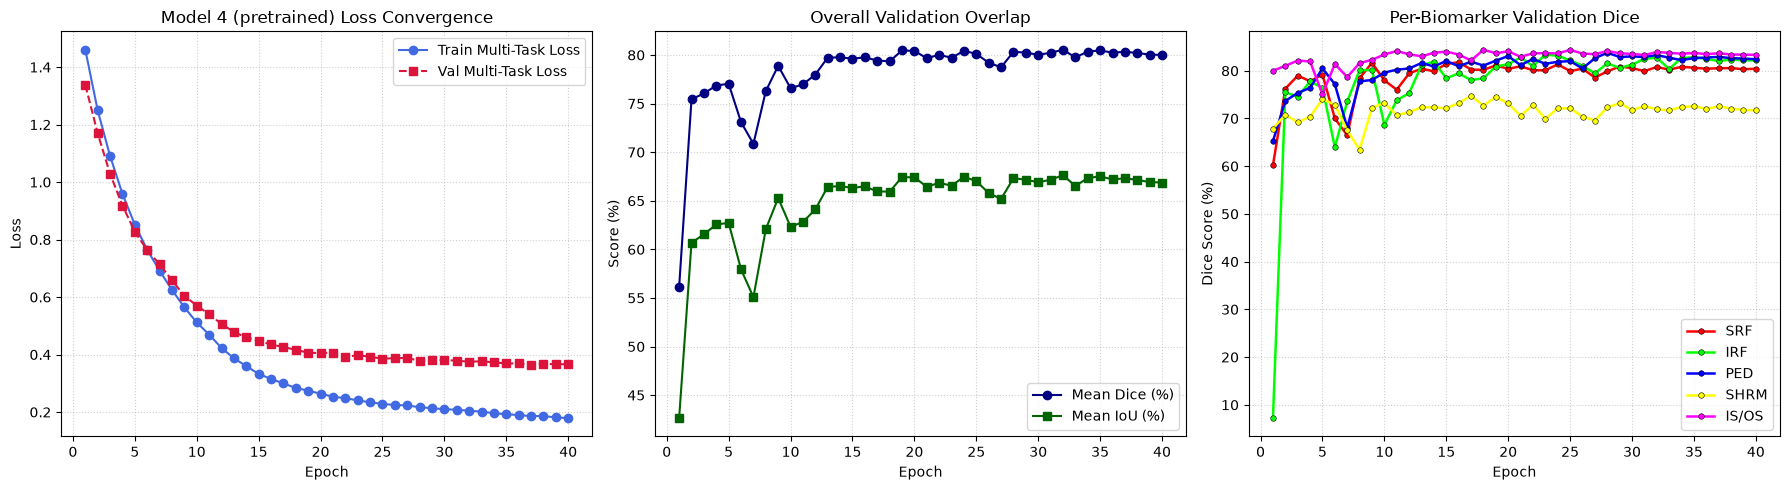

In [8]:
if os.path.exists(LOG_FILE):
    log_df = pd.read_csv(LOG_FILE)
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))

    axs[0].plot(log_df["epoch"], log_df["train_loss"], "o-", label="Train Multi-Task Loss", color="royalblue")
    axs[0].plot(log_df["epoch"], log_df["val_loss"], "s--", label="Val Multi-Task Loss", color="crimson")
    axs[0].set_title(f"Model 4 ({TAG}) Loss Convergence")
    axs[0].set_xlabel("Epoch"); axs[0].set_ylabel("Loss")
    axs[0].legend(); axs[0].grid(True, linestyle=":", alpha=0.6)

    axs[1].plot(log_df["epoch"], log_df["mean_dice"], "o-", label="Mean Dice (%)", color="navy")
    axs[1].plot(log_df["epoch"], log_df["mean_iou"], "s-", label="Mean IoU (%)", color="darkgreen")
    axs[1].set_title("Overall Validation Overlap")
    axs[1].set_xlabel("Epoch"); axs[1].set_ylabel("Score (%)")
    axs[1].legend(); axs[1].grid(True, linestyle=":", alpha=0.6)

    for lesion, pretty in zip(["SRF", "IRF", "PED", "SHRM", "IS_OS"], LESION_NAMES):
        axs[2].plot(log_df["epoch"], log_df[f"{lesion}_dice"], label=pretty, color=CLASS_COLORS_HEX[pretty],
                    marker="o", markersize=4, markeredgecolor="black", markeredgewidth=0.4, linewidth=1.8)
    axs[2].set_title("Per-Biomarker Validation Dice")
    axs[2].set_xlabel("Epoch"); axs[2].set_ylabel("Dice Score (%)")
    axs[2].legend(); axs[2].grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.savefig(f"{SAVE_PREFIX}_training_curves.png", dpi=200)
    plt.show()
else:
    print(f"'{LOG_FILE}' not found - train the model first.")

## 7. Quantitative Model 4 Benchmark Evaluation Report
Evaluates `best_unet_model4_<tag>.pth` on the validation split with the pixel-pooled `GlobalMetricTracker` and compares against:
* the **AMD-SD paper's U-Net baseline** (same reference values used in Models 2 and 3), and
* a **published TransUNet result on AMD-SD** (Table 1 of arXiv:2603.07889, a third-party paper that benchmarks on AMD-SD). *Treat this row as a rough reference only — its training recipe and evaluation details may differ from ours.*

Bars for Model 4 are coloured by lesion class (same palette as the segmentation maps); the two paper baselines are grey (solid = U-Net, hatched = TransUNet).

Loading Model 4 checkpoint: 'best_unet_model4_pretrained.pth'...


Evaluating Model 4 Benchmark: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 352/352 [02:11<00:00,  2.67it/s]



        WET AMD LESION SEGMENTATION: MODEL 4 (PRETRAINED) BENCHMARK REPORT  (pixel-pooled, validation split)
    Biomarker / Class  Paper U-Net Dice (%)  Paper TransUNet Dice (%)  Model 4 Dice (%) Dice Δ vs U-Net Dice Δ vs paper TransUNet  Paper U-Net IoU (%)  Paper TransUNet IoU (%)  Model 4 IoU (%) IoU Δ vs U-Net IoU Δ vs paper TransUNet
                  SRF                 78.65                     82.00             80.79          +2.145                    -1.205                64.81                    69.49            67.78         +2.968                   -1.712
                  IRF                 78.66                     74.85             82.73          +4.074                    +7.884                64.82                    59.81            70.55         +5.732                  +10.742
                  PED                 79.62                     78.93             83.28          +3.659                    +4.349                66.14                    65.19            71.3

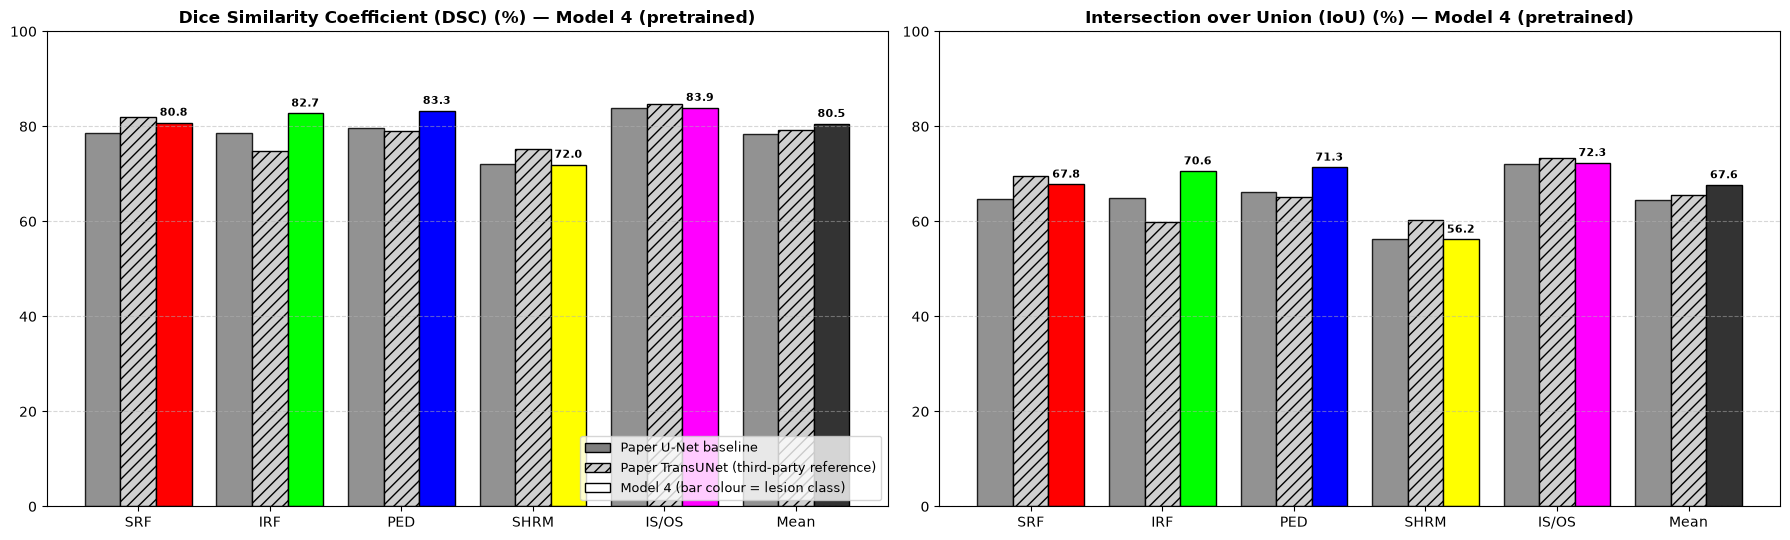

In [9]:
PAPER_UNET_DICE   = {"SRF": 78.65, "IRF": 78.66, "PED": 79.62, "SHRM": 72.10, "IS/OS": 83.76, "Mean": 78.40}
PAPER_UNET_IOU    = {"SRF": 64.81, "IRF": 64.82, "PED": 66.14, "SHRM": 56.37, "IS/OS": 72.06, "Mean": 64.48}
PAPER_TRANS_DICE  = {"SRF": 82.00, "IRF": 74.85, "PED": 78.93, "SHRM": 75.23, "IS/OS": 84.65, "Mean": 79.15}
PAPER_TRANS_IOU   = {"SRF": 69.49, "IRF": 59.81, "PED": 65.19, "SHRM": 60.29, "IS/OS": 73.39, "Mean": 65.49}


def run_model4_benchmark():
    cleanup_memory()
    print(f"Loading Model 4 checkpoint: '{CKPT_PATH}'...")
    eval_model = load_model4(CKPT_PATH)
    tracker = GlobalMetricTracker(num_classes=NUM_CLASSES)

    with torch.no_grad():
        for images, mc_targets, _ in tqdm(val_loader, desc="Evaluating Model 4 Benchmark"):
            images = images.to(device)
            mc_targets = mc_targets.to(device, dtype=torch.long)
            mc_logits, _ = eval_model(images)
            tracker.update(torch.argmax(mc_logits, dim=1), mc_targets)

    m_dice, m_iou, m_mean_dice, m_mean_iou = tracker.compute()
    m_dice["Mean"], m_iou["Mean"] = m_mean_dice, m_mean_iou

    rows = []
    for b in LESION_NAMES + ["Mean"]:
        rows.append({
            "Biomarker / Class": b if b != "Mean" else "Mean (All Biomarkers)",
            "Paper U-Net Dice (%)": PAPER_UNET_DICE[b],
            "Paper TransUNet Dice (%)": PAPER_TRANS_DICE[b],
            "Model 4 Dice (%)": round(m_dice[b], 2),
            "Dice Δ vs U-Net": f"{m_dice[b] - PAPER_UNET_DICE[b]:+.3f}",
            "Dice Δ vs paper TransUNet": f"{m_dice[b] - PAPER_TRANS_DICE[b]:+.3f}",
            "Paper U-Net IoU (%)": PAPER_UNET_IOU[b],
            "Paper TransUNet IoU (%)": PAPER_TRANS_IOU[b],
            "Model 4 IoU (%)": round(m_iou[b], 2),
            "IoU Δ vs U-Net": f"{m_iou[b] - PAPER_UNET_IOU[b]:+.3f}",
            "IoU Δ vs paper TransUNet": f"{m_iou[b] - PAPER_TRANS_IOU[b]:+.3f}",
        })
    benchmark_df = pd.DataFrame(rows)

    print("\n" + "=" * 120)
    print(f"        WET AMD LESION SEGMENTATION: MODEL 4 ({TAG.upper()}) BENCHMARK REPORT  (pixel-pooled, validation split)")
    print("=" * 120)
    print(benchmark_df.to_string(index=False))
    out_csv = f"{SAVE_PREFIX}_benchmark_report.csv"
    benchmark_df.to_csv(out_csv, index=False)
    print(f"\nSaved report to '{out_csv}'.")

    # Visual comparison
    cats = LESION_NAMES + ["Mean"]
    x = np.arange(len(cats))
    w = 0.27
    fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
    for ax, metric, unet, trans, ours in zip(
        axes, ["Dice Similarity Coefficient (DSC) (%)", "Intersection over Union (IoU) (%)"],
        [PAPER_UNET_DICE, PAPER_UNET_IOU], [PAPER_TRANS_DICE, PAPER_TRANS_IOU], [m_dice, m_iou]
    ):
        ax.bar(x - w, [unet[c] for c in cats], w, color="#7f7f7f", alpha=0.85, edgecolor="black")
        ax.bar(x, [trans[c] for c in cats], w, color="#cfcfcf", hatch="///", edgecolor="black")
        rects = ax.bar(x + w, [ours[c] for c in cats], w, color=[PLOT_COLORS[c] for c in cats], edgecolor="black")
        ax.set_title(f"{metric} — Model 4 ({TAG})", fontweight="bold")
        ax.set_xticks(x); ax.set_xticklabels(cats)
        ax.set_ylim(0, 100); ax.grid(axis="y", linestyle="--", alpha=0.5)
        for bar in rects:
            ax.annotate(f"{bar.get_height():.1f}", xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                        xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8, fontweight="bold")
    handles = [
        Patch(facecolor="#7f7f7f", edgecolor="black", label="Paper U-Net baseline"),
        Patch(facecolor="#cfcfcf", edgecolor="black", hatch="///", label="Paper TransUNet (third-party reference)"),
        Patch(facecolor="white", edgecolor="black", label="Model 4 (bar colour = lesion class)"),
    ]
    axes[0].legend(handles=handles, loc="lower right", fontsize=9)
    plt.tight_layout()
    plt.savefig(f"{SAVE_PREFIX}_benchmark_bars.png", dpi=200)
    plt.show()

    del eval_model
    cleanup_memory()
    return benchmark_df

benchmark_df = run_model4_benchmark()

## 8. Qualitative Visualizations: Ground Truth vs. Multi-Class & Binary Predictions
Renders the classic **2 × 4 grid** (2 validation scans × [input OCT, ground truth, binary lesion probability, multi-class prediction]) **with a class legend** (meeting note). Masks are drawn with the project palette rather than a generic colormap, so colours match every other figure. Scans are chosen automatically from slices that actually contain at least two lesion classes (a random first batch is often lesion-free and uninformative).

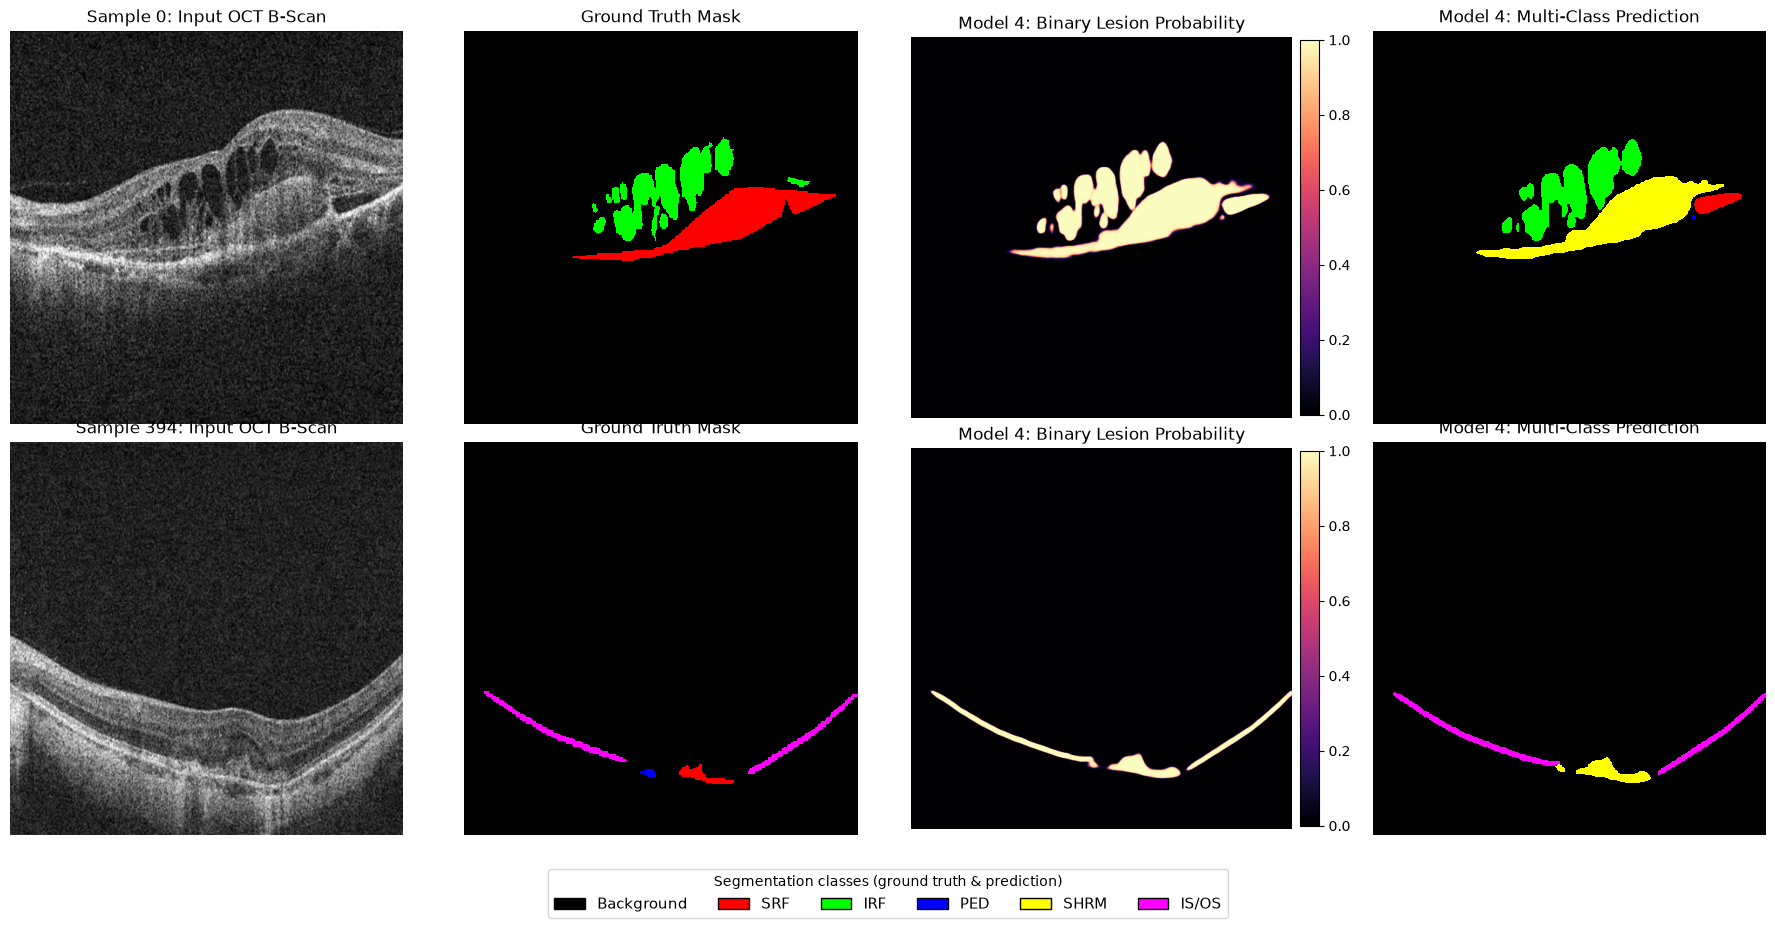

In [10]:
def find_lesion_samples(dataset, n=2, min_lesion_classes=2, max_scan=400):
    """Return `n` evenly spread dataset indices whose ground truth contains >= min_lesion_classes lesion classes."""
    found = []
    for i in range(min(len(dataset), max_scan)):
        _, m, _ = dataset[i]
        if int((torch.unique(m) > 0).sum()) >= min_lesion_classes:
            found.append(i)
    if not found:
        return list(range(n))
    pos = np.linspace(0, len(found) - 1, n).round().astype(int)
    return list(dict.fromkeys(found[p] for p in pos))


def visualize_model4_predictions(num_samples=2, split="val"):
    ds = AMDDatasetModel4(DATA_DIR, split=split, target_size=(IMG_SIZE, IMG_SIZE), augment=False)
    idxs = find_lesion_samples(ds, n=num_samples)
    eval_model = load_model4(CKPT_PATH)

    items = [ds[i] for i in idxs]
    batch = torch.stack([it[0] for it in items]).to(device)
    with torch.no_grad():
        mc_logits, bin_logits = eval_model(batch)
    pred_mc = torch.argmax(mc_logits, dim=1).cpu().numpy()
    pred_bin = torch.sigmoid(bin_logits).squeeze(1).cpu().numpy()

    n = len(idxs)
    fig, axs = plt.subplots(n, 4, figsize=(18, 4.6 * n), squeeze=False)
    for r, (idx, (img, gt, _)) in enumerate(zip(idxs, items)):
        axs[r, 0].imshow(img[0].numpy(), cmap="gray"); axs[r, 0].set_title(f"Sample {idx}: Input OCT B-Scan"); axs[r, 0].axis("off")
        show_seg(axs[r, 1], gt.numpy(), "Ground Truth Mask")
        im = axs[r, 2].imshow(pred_bin[r], cmap="magma", vmin=0.0, vmax=1.0)
        axs[r, 2].set_title("Model 4: Binary Lesion Probability"); axs[r, 2].axis("off")
        fig.colorbar(im, ax=axs[r, 2], fraction=0.046, pad=0.02)
        show_seg(axs[r, 3], pred_mc[r], "Model 4: Multi-Class Prediction")

    fig.legend(handles=seg_legend_handles(), loc="lower center", ncol=len(CLASS_NAMES), frameon=True,
               title="Segmentation classes (ground truth & prediction)", fontsize=11)
    plt.tight_layout(rect=[0, 0.08, 1, 1])
    plt.savefig(f"{SAVE_PREFIX}_qualitative_2x4.png", dpi=200)
    plt.show()
    del eval_model
    cleanup_memory()

visualize_model4_predictions(num_samples=2)

## 9. Statistical Evaluation: Per-Image Distributions, 99% Bootstrapped Confidence Intervals & Class-Coloured Plots

All per-image statistics are derived from one compact **raw data structure**: for every test slice, a $6 \times 6$ pixel confusion matrix (rows = ground truth, columns = prediction). From it we can recover, per class, the intersection, prediction size and ground-truth size, and therefore Dice / IoU under any scoring convention — without re-running the network. The confusion matrices are cached (`<model>_<split>_per_image_cm.npz`) and automatically invalidated if the checkpoint changes.

**Why the scoring convention matters (double-check of Models 1–3).** A B-scan often contains no pixels of a given class (e.g. no SHRM) in either the ground truth or the prediction. The earlier notebooks handled this *differently*:

| Convention | Slices where class is absent in **both** GT and prediction | Used by |
|---|---|---|
| `exclude` | dropped (`NaN`) | Model 2 |
| `credit` | scored as 100 % | Models 1 and 3 |
| `gt_present` | only slices whose **ground truth** contains the class are scored (false positives on GT-absent slices are ignored) | new — "how well is the class segmented *when it exists*" |

Because these slices are numerous, `credit` pushes means and the box position of rare classes upward, so Model 2 and Model 3 boxplots from the earlier notebooks are **not directly comparable**. Here `exclude` is the primary convention (it is the stricter of the two and matches Model 2); all three are computed, saved, and compared in §12.

**Plots (meeting note):**
* **Boxplot with the raw per-image points overlaid** (the actual value distribution; diamond = mean).
* **Confidence-interval plot**: mean ± 99 % bootstrap CI per class.
* Box / CI colours = the segmentation-mask colours of each class.

In [11]:
EVAL_CONVENTIONS = {
    "exclude":    "class absent in BOTH GT and prediction -> slice dropped (NaN)   [Model 2 convention]",
    "credit":     "class absent in BOTH GT and prediction -> slice scores 100%     [Model 1 / Model 3 convention]",
    "gt_present": "only slices whose GROUND TRUTH contains the class are scored",
}
PRIMARY_CONVENTION = "exclude"
PLOT_CLASSES = LESION_NAMES + ["Mean"]


def resolve_eval_split(preferred="test"):
    """Use the test split if it exists, otherwise fall back to val (with a loud warning)."""
    if os.path.exists(os.path.join(DATA_DIR, preferred, "inputs")):
        return preferred
    print(f"WARNING: '{os.path.join(DATA_DIR, preferred, 'inputs')}' not found -> falling back to the 'val' split. "
          f"Note that 'val' was used for checkpoint selection, so these numbers are optimistic.")
    return "val"


@torch.no_grad()
def collect_confusions(model, loader, mc_fn, num_classes=6, desc=""):
    """Per-image pixel confusion matrices cms[i, gt, pred] plus simple image statistics."""
    model.eval()
    cms, means, stds = [], [], []
    for images, targets, _ in tqdm(loader, desc=desc):
        images_d = images.to(device)
        preds = mc_fn(model(images_d)).argmax(dim=1).cpu()
        flat = images.flatten(1)
        means.append(flat.mean(dim=1).numpy()); stds.append(flat.std(dim=1).numpy())
        for b in range(preds.shape[0]):
            idx = targets[b].reshape(-1) * num_classes + preds[b].reshape(-1)
            cms.append(torch.bincount(idx, minlength=num_classes ** 2).reshape(num_classes, num_classes).numpy())
    return np.stack(cms).astype(np.int64), np.concatenate(means), np.concatenate(stds)


def get_per_image_cms(model_key, build_fn, ckpt_path, mc_fn, split, max_images=None, use_cache=True):
    """
    Returns (cms [N,6,6], meta DataFrame[dataset_idx, filename, img_mean, img_std]).
    Cached in '<model_key>_<split>[_n<max_images>]_per_image_cm.npz'; the cache is ignored if the checkpoint is newer.
    """
    suffix = f"_n{max_images}" if max_images else ""
    cache_path = f"{model_key}_{split}{suffix}_per_image_cm.npz"
    ckpt_mtime = os.path.getmtime(ckpt_path)

    if use_cache and os.path.exists(cache_path):
        z = np.load(cache_path)
        if float(z["ckpt_mtime"]) == ckpt_mtime:
            print(f"[cache] loaded per-image confusion matrices from '{cache_path}'")
            meta = pd.DataFrame({"dataset_idx": z["dataset_idx"], "filename": z["filenames"],
                                 "img_mean": z["img_mean"], "img_std": z["img_std"]})
            return z["cms"], meta
        print(f"[cache] '{cache_path}' is stale (checkpoint changed) -> recomputing")

    ds = AMDDatasetModel4(DATA_DIR, split=split, target_size=(IMG_SIZE, IMG_SIZE), augment=False)
    indices = np.arange(len(ds))
    if max_images and max_images < len(ds):
        indices = np.sort(np.random.default_rng(SEED).choice(len(ds), size=max_images, replace=False))
    loader = DataLoader(Subset(ds, indices.tolist()), batch_size=VAL_BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

    net = build_fn().to(device)
    net.load_state_dict(torch.load(ckpt_path, map_location=device))
    cms, img_mean, img_std = collect_confusions(net, loader, mc_fn, num_classes=NUM_CLASSES,
                                                desc=f"Evaluating {model_key} [{split}]")
    del net
    cleanup_memory()

    filenames = np.array([ds.filenames[i] for i in indices])
    np.savez_compressed(cache_path, cms=cms, dataset_idx=indices, filenames=filenames,
                        img_mean=img_mean, img_std=img_std, ckpt_mtime=ckpt_mtime)
    meta = pd.DataFrame({"dataset_idx": indices, "filename": filenames, "img_mean": img_mean, "img_std": img_std})
    return cms, meta


def per_image_metrics(cms, convention=PRIMARY_CONVENTION):
    """Per-image, per-class Dice / IoU (in %) from confusion matrices under a given scoring convention."""
    assert convention in EVAL_CONVENTIONS, f"unknown convention '{convention}'"
    out = {}
    for c, name in enumerate(LESION_NAMES, start=1):
        inter = cms[:, c, c].astype(np.float64)
        t_sum = cms[:, c, :].sum(axis=1).astype(np.float64)       # GT pixels of class c
        p_sum = cms[:, :, c].sum(axis=1).astype(np.float64)       # predicted pixels of class c
        union = t_sum + p_sum - inter
        denom = t_sum + p_sum
        dice = np.where(denom > 0, 2.0 * inter / np.maximum(denom, 1.0), np.nan) * 100.0
        iou = np.where(union > 0, inter / np.maximum(union, 1.0), np.nan) * 100.0
        both_empty = denom == 0
        if convention == "credit":
            dice[both_empty] = 100.0; iou[both_empty] = 100.0
        elif convention == "gt_present":
            dice[t_sum == 0] = np.nan; iou[t_sum == 0] = np.nan
        out[f"{name}_DSC"] = dice
        out[f"{name}_IoU"] = iou
    df = pd.DataFrame(out)
    df["Mean_DSC"] = df[[f"{n}_DSC" for n in LESION_NAMES]].mean(axis=1, skipna=True)
    df["Mean_IoU"] = df[[f"{n}_IoU" for n in LESION_NAMES]].mean(axis=1, skipna=True)
    return df


def bootstrap_ci(values, n_boot=2000, ci=0.99, seed=SEED, chunk=250):
    """Non-parametric percentile bootstrap CI of the mean. Returns (mean, lo, hi, n)."""
    v = np.asarray(values, dtype=np.float64)
    v = v[~np.isnan(v)]
    if v.size == 0:
        return np.nan, np.nan, np.nan, 0
    rng = np.random.default_rng(seed)
    means = np.empty(n_boot)
    for s in range(0, n_boot, chunk):
        e = min(n_boot, s + chunk)
        means[s:e] = v[rng.integers(0, v.size, size=(e - s, v.size))].mean(axis=1)
    a = (1.0 - ci) / 2.0 * 100.0
    return float(v.mean()), float(np.percentile(means, a)), float(np.percentile(means, 100.0 - a)), int(v.size)


def summarize_ci(df_metrics, n_boot=2000, ci=0.99):
    rows = []
    for metric_suffix, metric_name in [("DSC", "DSC"), ("IoU", "IoU")]:
        for c in PLOT_CLASSES:
            vals = df_metrics[f"{c}_{metric_suffix}"].to_numpy()
            mean, lo, hi, n = bootstrap_ci(vals, n_boot=n_boot, ci=ci)
            clean = vals[~np.isnan(vals)]
            rows.append({
                "Class": c, "Metric": metric_name, "N slices": n,
                "Mean (%)": round(mean, 2), "Median (%)": round(float(np.median(clean)), 2) if n else np.nan,
                "Std (%)": round(float(clean.std(ddof=1)), 2) if n > 1 else np.nan,
                f"{int(ci * 100)}% CI Lower": round(lo, 2), f"{int(ci * 100)}% CI Upper": round(hi, 2),
            })
    return pd.DataFrame(rows)


# ------------------------------------- plotting -------------------------------------
def plot_boxplots_raw(df_metrics, title, save_path=None, show_raw=True):
    """Per-class boxplots (class colours) with the raw per-image values overlaid; diamond = mean."""
    fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)
    rng = np.random.default_rng(0)
    for ax, (suffix, label) in zip(axes, [("DSC", "Dice Similarity Coefficient (DSC)"), ("IoU", "Intersection over Union (IoU)")]):
        data = [df_metrics[f"{c}_{suffix}"].dropna().to_numpy() for c in PLOT_CLASSES]
        bp = ax.boxplot(
            data, positions=np.arange(1, len(data) + 1), patch_artist=True, widths=0.55, showmeans=True,
            meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 7},
            medianprops={"color": "black", "linewidth": 2},
            flierprops={"marker": "" if show_raw else "o", "markersize": 3, "alpha": 0.35},
        )
        for patch, c in zip(bp["boxes"], PLOT_CLASSES):
            patch.set_facecolor(to_rgba(PLOT_COLORS[c], 0.55)); patch.set_edgecolor("black"); patch.set_linewidth(1.3)
        if show_raw:
            for i, vals in enumerate(data, start=1):
                ax.scatter(i + rng.uniform(-0.22, 0.22, size=len(vals)), vals, s=7, color="black", alpha=0.17, linewidths=0, zorder=3)
        ax.set_xticks(np.arange(1, len(data) + 1))
        ax.set_xticklabels([f"{c}\n(n={len(d)})" for c, d in zip(PLOT_CLASSES, data)])
        ax.set_title(f"{title}\n{label} per image", fontsize=12, fontweight="bold")
        ax.set_ylabel(f"{label} (%)"); ax.set_xlabel("Biomarker (box colour = class colour in segmentation maps)")
        ax.set_ylim(-3, 106); ax.grid(axis="y", linestyle="--", alpha=0.6)
        for i, vals in enumerate(data, start=1):
            if len(vals):
                ax.text(i, 102.5, f"{vals.mean():.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=250)
    plt.show()


def plot_ci_estimates(df_ci, title, save_path=None):
    """Mean with 99% bootstrap CI per class, coloured like the segmentation classes."""
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    ci_lo_col = [c for c in df_ci.columns if c.endswith("CI Lower")][0]
    ci_hi_col = [c for c in df_ci.columns if c.endswith("CI Upper")][0]
    ci_label = ci_lo_col.replace(" CI Lower", "")
    for ax, metric in zip(axes, ["DSC", "IoU"]):
        sub = df_ci[df_ci["Metric"] == metric].set_index("Class").loc[PLOT_CLASSES]
        for i, c in enumerate(PLOT_CLASSES):
            m, lo, hi = sub.loc[c, "Mean (%)"], sub.loc[c, ci_lo_col], sub.loc[c, ci_hi_col]
            yerr = [[m - lo], [hi - m]]
            ax.errorbar(i, m, yerr=yerr, fmt="none", ecolor="black", elinewidth=6, capsize=9, capthick=3, zorder=2)   # outline
            ax.errorbar(i, m, yerr=yerr, fmt="o", color=PLOT_COLORS[c], ecolor=PLOT_COLORS[c], elinewidth=3.5, capsize=7,
                        capthick=2, markersize=11, markeredgecolor="black", markeredgewidth=1.2, zorder=3)
            ax.annotate(f"{m:.1f}\n[{lo:.1f}, {hi:.1f}]", (i, hi), xytext=(0, 8), textcoords="offset points",
                        ha="center", va="bottom", fontsize=9)
        ax.set_xticks(range(len(PLOT_CLASSES)))
        ax.set_xticklabels([f"{c}\n(n={int(sub.loc[c, 'N slices'])})" for c in PLOT_CLASSES])
        lo_all, hi_all = sub[ci_lo_col].min(), sub[ci_hi_col].max()
        pad = max(4.0, 0.15 * (hi_all - lo_all))
        ax.set_ylim(max(0, lo_all - pad), min(100, hi_all + pad + 6))
        ax.set_xlim(-0.6, len(PLOT_CLASSES) - 0.4)
        ax.set_ylabel(f"Mean {metric} (%)"); ax.set_xlabel("Biomarker")
        ax.set_title(f"{title}\nMean {metric} with {ci_label} bootstrap CI", fontsize=12, fontweight="bold")
        ax.grid(axis="y", linestyle="--", alpha=0.6)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=250)
    plt.show()

Evaluating Model 4 (pretrained) on split 'val'...
[cache] 'model4_pretrained_val_per_image_cm.npz' is stale (checkpoint changed) -> recomputing


Evaluating model4_pretrained [val]: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████| 352/352 [02:09<00:00,  2.73it/s]


Saved raw per-image pixel counts to 'model4_pretrained_val_per_image_raw_counts.csv'.

  MODEL 4 (pretrained) — 99% BOOTSTRAPPED CIs (2000 resamples) | split='val' | convention='exclude'
Class Metric  N slices  Mean (%)  Median (%)  Std (%)  99% CI Lower  99% CI Upper
  SRF    DSC       452     65.79       84.21    35.72         61.30         69.87
  IRF    DSC       179     55.37       74.36    37.86         47.93         62.29
  PED    DSC       503     58.72       76.73    36.69         54.52         62.74
 SHRM    DSC       428     56.26       71.97    36.76         51.84         60.69
IS/OS    DSC       636     74.58       85.20    26.61         71.67         77.26
 Mean    DSC       703     66.26       70.49    22.11         64.05         68.40
  SRF    IoU       452     58.04       72.73    34.32         53.72         61.99
  IRF    IoU       179     47.10       59.18    34.23         40.64         53.91
  PED    IoU       503     50.26       62.25    33.95         46.42        

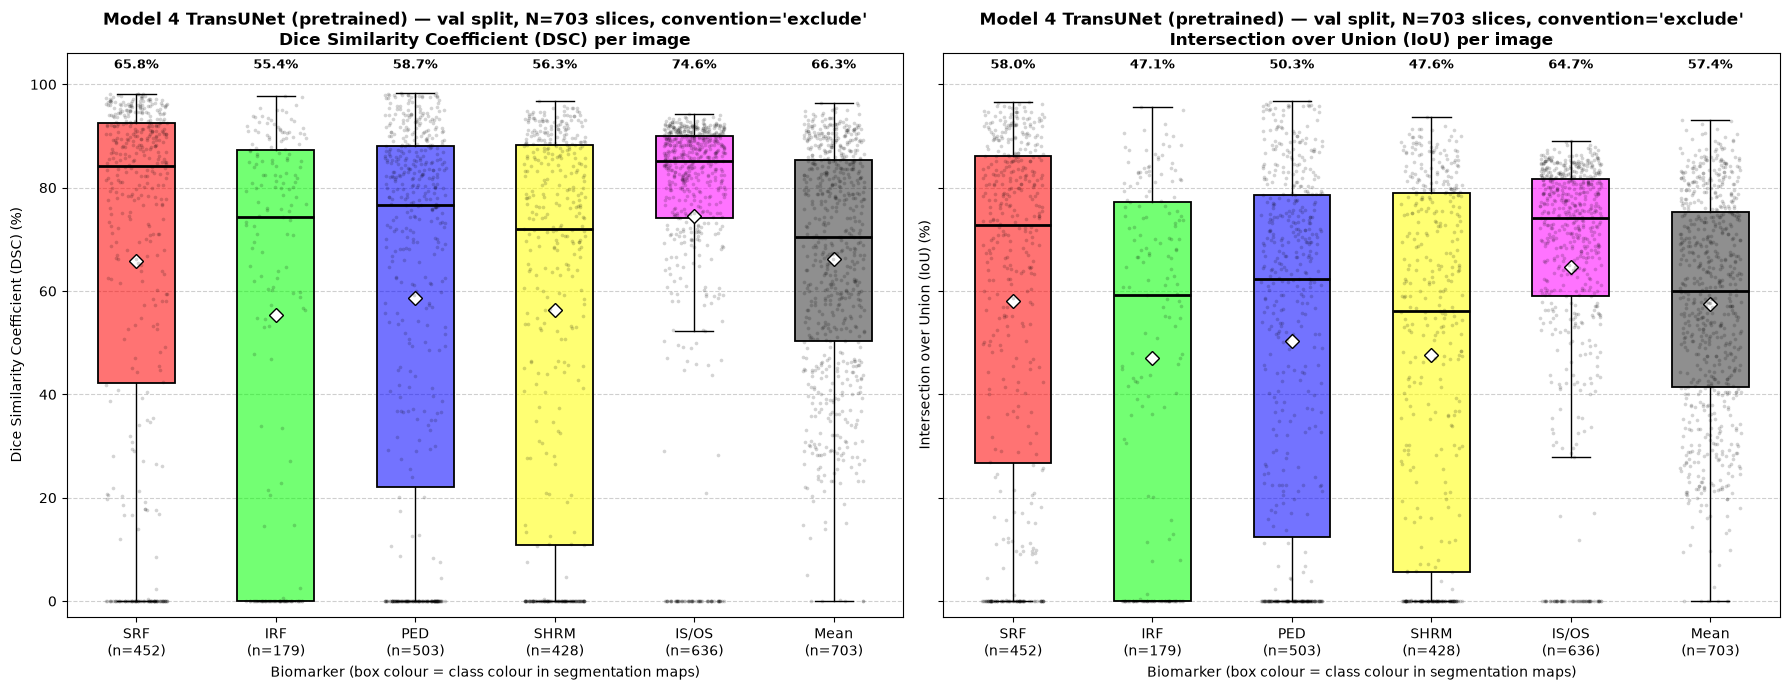

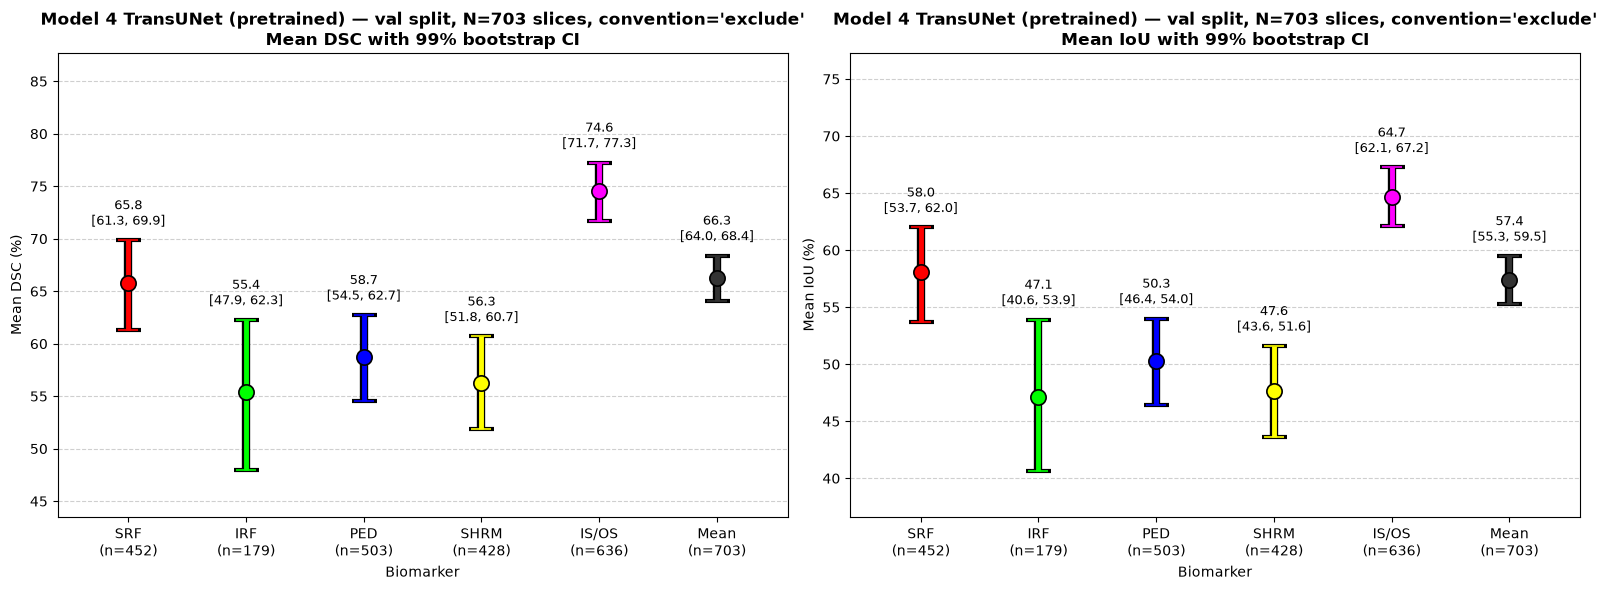

In [12]:
def run_model4_statistical_eval(split_pref="test", n_boot=2000):
    split = resolve_eval_split(split_pref)
    print(f"Evaluating Model 4 ({TAG}) on split '{split}'...")
    cms, meta = get_per_image_cms(MODEL_KEY, lambda: TransUNetDualHead(pretrained=False, img_size=IMG_SIZE),
                                  CKPT_PATH, lambda out: out[0], split)

    # ---- Raw data export: per-image, per-class pixel counts (GT size, prediction size, intersection) ----
    raw = meta.copy()
    for c, name in enumerate(LESION_NAMES, start=1):
        raw[f"{name}_GT_px"] = cms[:, c, :].sum(axis=1)
        raw[f"{name}_Pred_px"] = cms[:, :, c].sum(axis=1)
        raw[f"{name}_Inter_px"] = cms[:, c, c]
    raw_csv = f"{SAVE_PREFIX}_{split}_per_image_raw_counts.csv"
    raw.to_csv(raw_csv, index=False)
    print(f"Saved raw per-image pixel counts to '{raw_csv}'.")

    # ---- Per-image metrics under every convention, saved to disk ----
    metrics = {}
    for conv in EVAL_CONVENTIONS:
        df_m = per_image_metrics(cms, conv)
        metrics[conv] = df_m
        out = pd.concat([meta[["filename"]], df_m], axis=1)
        out.to_csv(f"{SAVE_PREFIX}_{split}_per_image_scores_{conv}.csv", index=False)

    # ---- Primary convention: CI table + plots ----
    df_ci = summarize_ci(metrics[PRIMARY_CONVENTION], n_boot=n_boot)
    ci_csv = f"{SAVE_PREFIX}_{split}_bootstrapped_99_ci_{PRIMARY_CONVENTION}.csv"
    df_ci.to_csv(ci_csv, index=False)
    print("\n" + "=" * 100)
    print(f"  MODEL 4 ({TAG}) — 99% BOOTSTRAPPED CIs ({n_boot} resamples) | split='{split}' | convention='{PRIMARY_CONVENTION}'")
    print("=" * 100)
    print(df_ci.to_string(index=False))
    print(f"\nSaved to '{ci_csv}'.")

    # ---- How much does the convention change the answer? (mean DSC) ----
    gap = pd.DataFrame({conv: {c: np.nanmean(metrics[conv][f"{c}_DSC"].to_numpy()) for c in PLOT_CLASSES}
                        for conv in EVAL_CONVENTIONS}).round(2)
    gap["credit − exclude"] = (gap["credit"] - gap["exclude"]).round(2)
    print("\nMean DSC (%) per class under each scoring convention:")
    print(gap.to_string())

    title = f"Model 4 TransUNet ({TAG}) — {split} split, N={len(cms)} slices, convention='{PRIMARY_CONVENTION}'"
    plot_boxplots_raw(metrics[PRIMARY_CONVENTION], title, save_path=f"{SAVE_PREFIX}_{split}_boxplots_raw.png")
    plot_ci_estimates(df_ci, title, save_path=f"{SAVE_PREFIX}_{split}_ci_plot.png")
    return cms, meta, split

M4_CMS, M4_META, M4_SPLIT = run_model4_statistical_eval(split_pref="test", n_boot=2000)

## 10. Pixel-Level Confusion Matrix
Every pixel of every evaluation slice is one observation (rows = ground truth, columns = prediction), aggregated from the per-image confusion matrices computed in §9.

* **Left:** the full $6 \times 6$ matrix including *Background*, row-normalised (each row sums to 100 % → per-class recall on the diagonal). Background is kept because most lesion errors are "lesion ↔ background" mistakes and would otherwise be invisible.
* **Right:** the **5-class lesion-only** matrix: only ground-truth lesion pixels that the network *also* labelled as some lesion class, re-normalised per row. This isolates **which lesion classes get mistaken for each other**, once "missed entirely" is factored out.

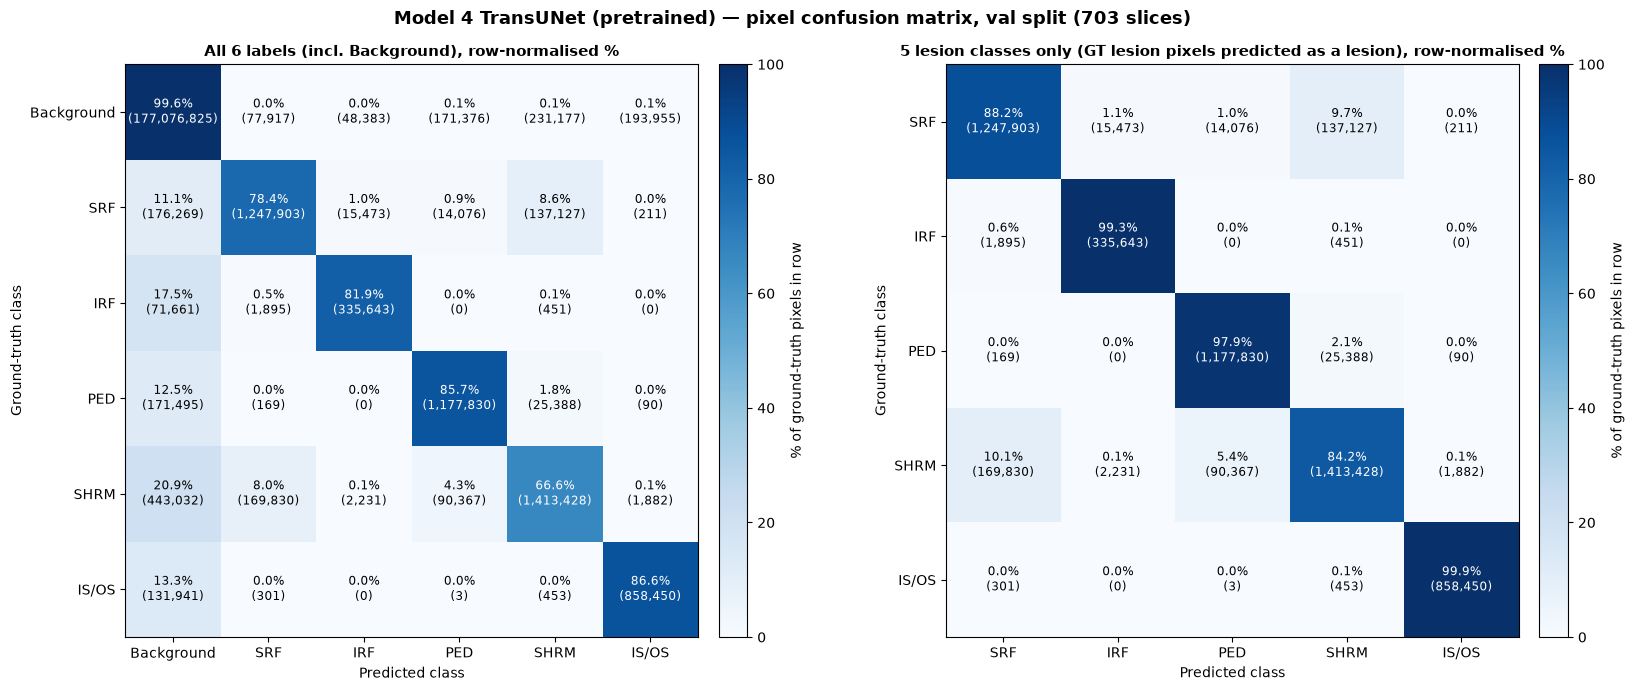


Top-8 confusions (share of the ground-truth class labelled as the other class):
  GT SHRM       -> predicted Background:  20.89%
  GT IRF        -> predicted Background:  17.49%
  GT IS/OS      -> predicted Background:  13.31%
  GT PED        -> predicted Background:  12.47%
  GT SRF        -> predicted Background:  11.08%
  GT SRF        -> predicted SHRM      :   8.62%
  GT SHRM       -> predicted SRF       :   8.01%
  GT SHRM       -> predicted PED       :   4.26%


In [13]:
def plot_confusion_matrix(cm, title, save_path=None):
    n6 = cm.astype(np.float64)
    row6 = n6.sum(axis=1, keepdims=True)
    norm6 = np.divide(n6, row6, out=np.zeros_like(n6), where=row6 > 0) * 100.0

    cm5 = n6[1:, 1:]
    row5 = cm5.sum(axis=1, keepdims=True)
    norm5 = np.divide(cm5, row5, out=np.zeros_like(cm5), where=row5 > 0) * 100.0

    fig, axes = plt.subplots(1, 2, figsize=(17, 7))
    panels = [
        (axes[0], norm6, n6, CLASS_NAMES, "All 6 labels (incl. Background), row-normalised %"),
        (axes[1], norm5, cm5, LESION_NAMES, "5 lesion classes only (GT lesion pixels predicted as a lesion), row-normalised %"),
    ]
    for ax, norm, counts, names, sub in panels:
        im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=100)
        for i in range(len(names)):
            for j in range(len(names)):
                col = "white" if norm[i, j] > 55 else "black"
                ax.text(j, i, f"{norm[i, j]:.1f}%\n({int(counts[i, j]):,})", ha="center", va="center", color=col, fontsize=8.5)
        ax.set_xticks(range(len(names))); ax.set_yticks(range(len(names)))
        ax.set_xticklabels(names); ax.set_yticklabels(names)
        ax.set_xlabel("Predicted class"); ax.set_ylabel("Ground-truth class")
        ax.set_title(sub, fontsize=11, fontweight="bold")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label="% of ground-truth pixels in row")
    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=250)
    plt.show()
    return norm6, norm5


cm_total = M4_CMS.sum(axis=0)
norm6, norm5 = plot_confusion_matrix(
    cm_total, f"Model 4 TransUNet ({TAG}) — pixel confusion matrix, {M4_SPLIT} split ({len(M4_CMS)} slices)",
    save_path=f"{SAVE_PREFIX}_{M4_SPLIT}_confusion_matrix.png")

pd.DataFrame(cm_total, index=[f"GT:{n}" for n in CLASS_NAMES], columns=[f"Pred:{n}" for n in CLASS_NAMES]) \
  .to_csv(f"{SAVE_PREFIX}_{M4_SPLIT}_confusion_matrix_counts.csv")

# Most frequent mistakes, as a fraction of each ground-truth class
conf = pd.DataFrame(norm6, index=CLASS_NAMES, columns=CLASS_NAMES)
pairs = [(g, p, conf.loc[g, p]) for g in CLASS_NAMES for p in CLASS_NAMES if g != p]
print("\nTop-8 confusions (share of the ground-truth class labelled as the other class):")
for g, p, v in sorted(pairs, key=lambda t: -t[2])[:8]:
    print(f"  GT {g:<10} -> predicted {p:<10}: {v:6.2f}%")

## 11. Error Analysis: Low-Dice / Low-IoU Examples from the TRAIN or VAL Set
As suggested in the meeting, we look at the *worst* slices on **train or validation data — never the test set** — to see whether there are visible reasons for poor performance, without tuning on the test set.

For the chosen split the cell:
1. Ranks slices by Dice over the lesion classes present in the ground truth (or by a single `focus_class`).
2. Plots the worst `k` slices as **Input / Ground truth / Prediction / Error map**. The error map uses colours that are *not* in the class palette, so they cannot be confused with lesion classes: orange = lesion missed (predicted background), white = false alarm (predicted lesion on background), cyan = wrong lesion class, dark grey = correct.
3. Tests simple hypotheses with Spearman correlations and plots: is Dice driven by lesion size, number of classes present, or image brightness / contrast?

Use `split="train"` with `max_images=800` to run the same analysis on a random subset of the training data. A big train/val gap in these statistics points to over-fitting rather than data difficulty.

[cache] loaded per-image confusion matrices from 'model4_pretrained_val_per_image_cm.npz'
[val] 703/703 slices have the scored class(es) present in the ground truth.

Worst 6 slices by Mean Dice:
 dataset_idx         filename GT_classes  GT_lesion_px  Pred_lesion_px  Mean Dice (%)  Mean IoU (%)  img_mean  img_std  Pred/GT area
         117  104_6_input.png       SHRM           879            1052           0.00          0.00      0.22     0.17          1.20
         146  105_5_input.png        SRF           153              12           0.00          0.00      0.20     0.17          0.08
         148  105_7_input.png        SRF           716               0           0.00          0.00      0.20     0.17          0.00
         151 106_10_input.png       SHRM          5238            4783           0.00          0.00      0.22     0.19          0.91
         485 120_12_input.png  PED, SHRM         12638            9789           0.02          0.01      0.19     0.13          0.77
      

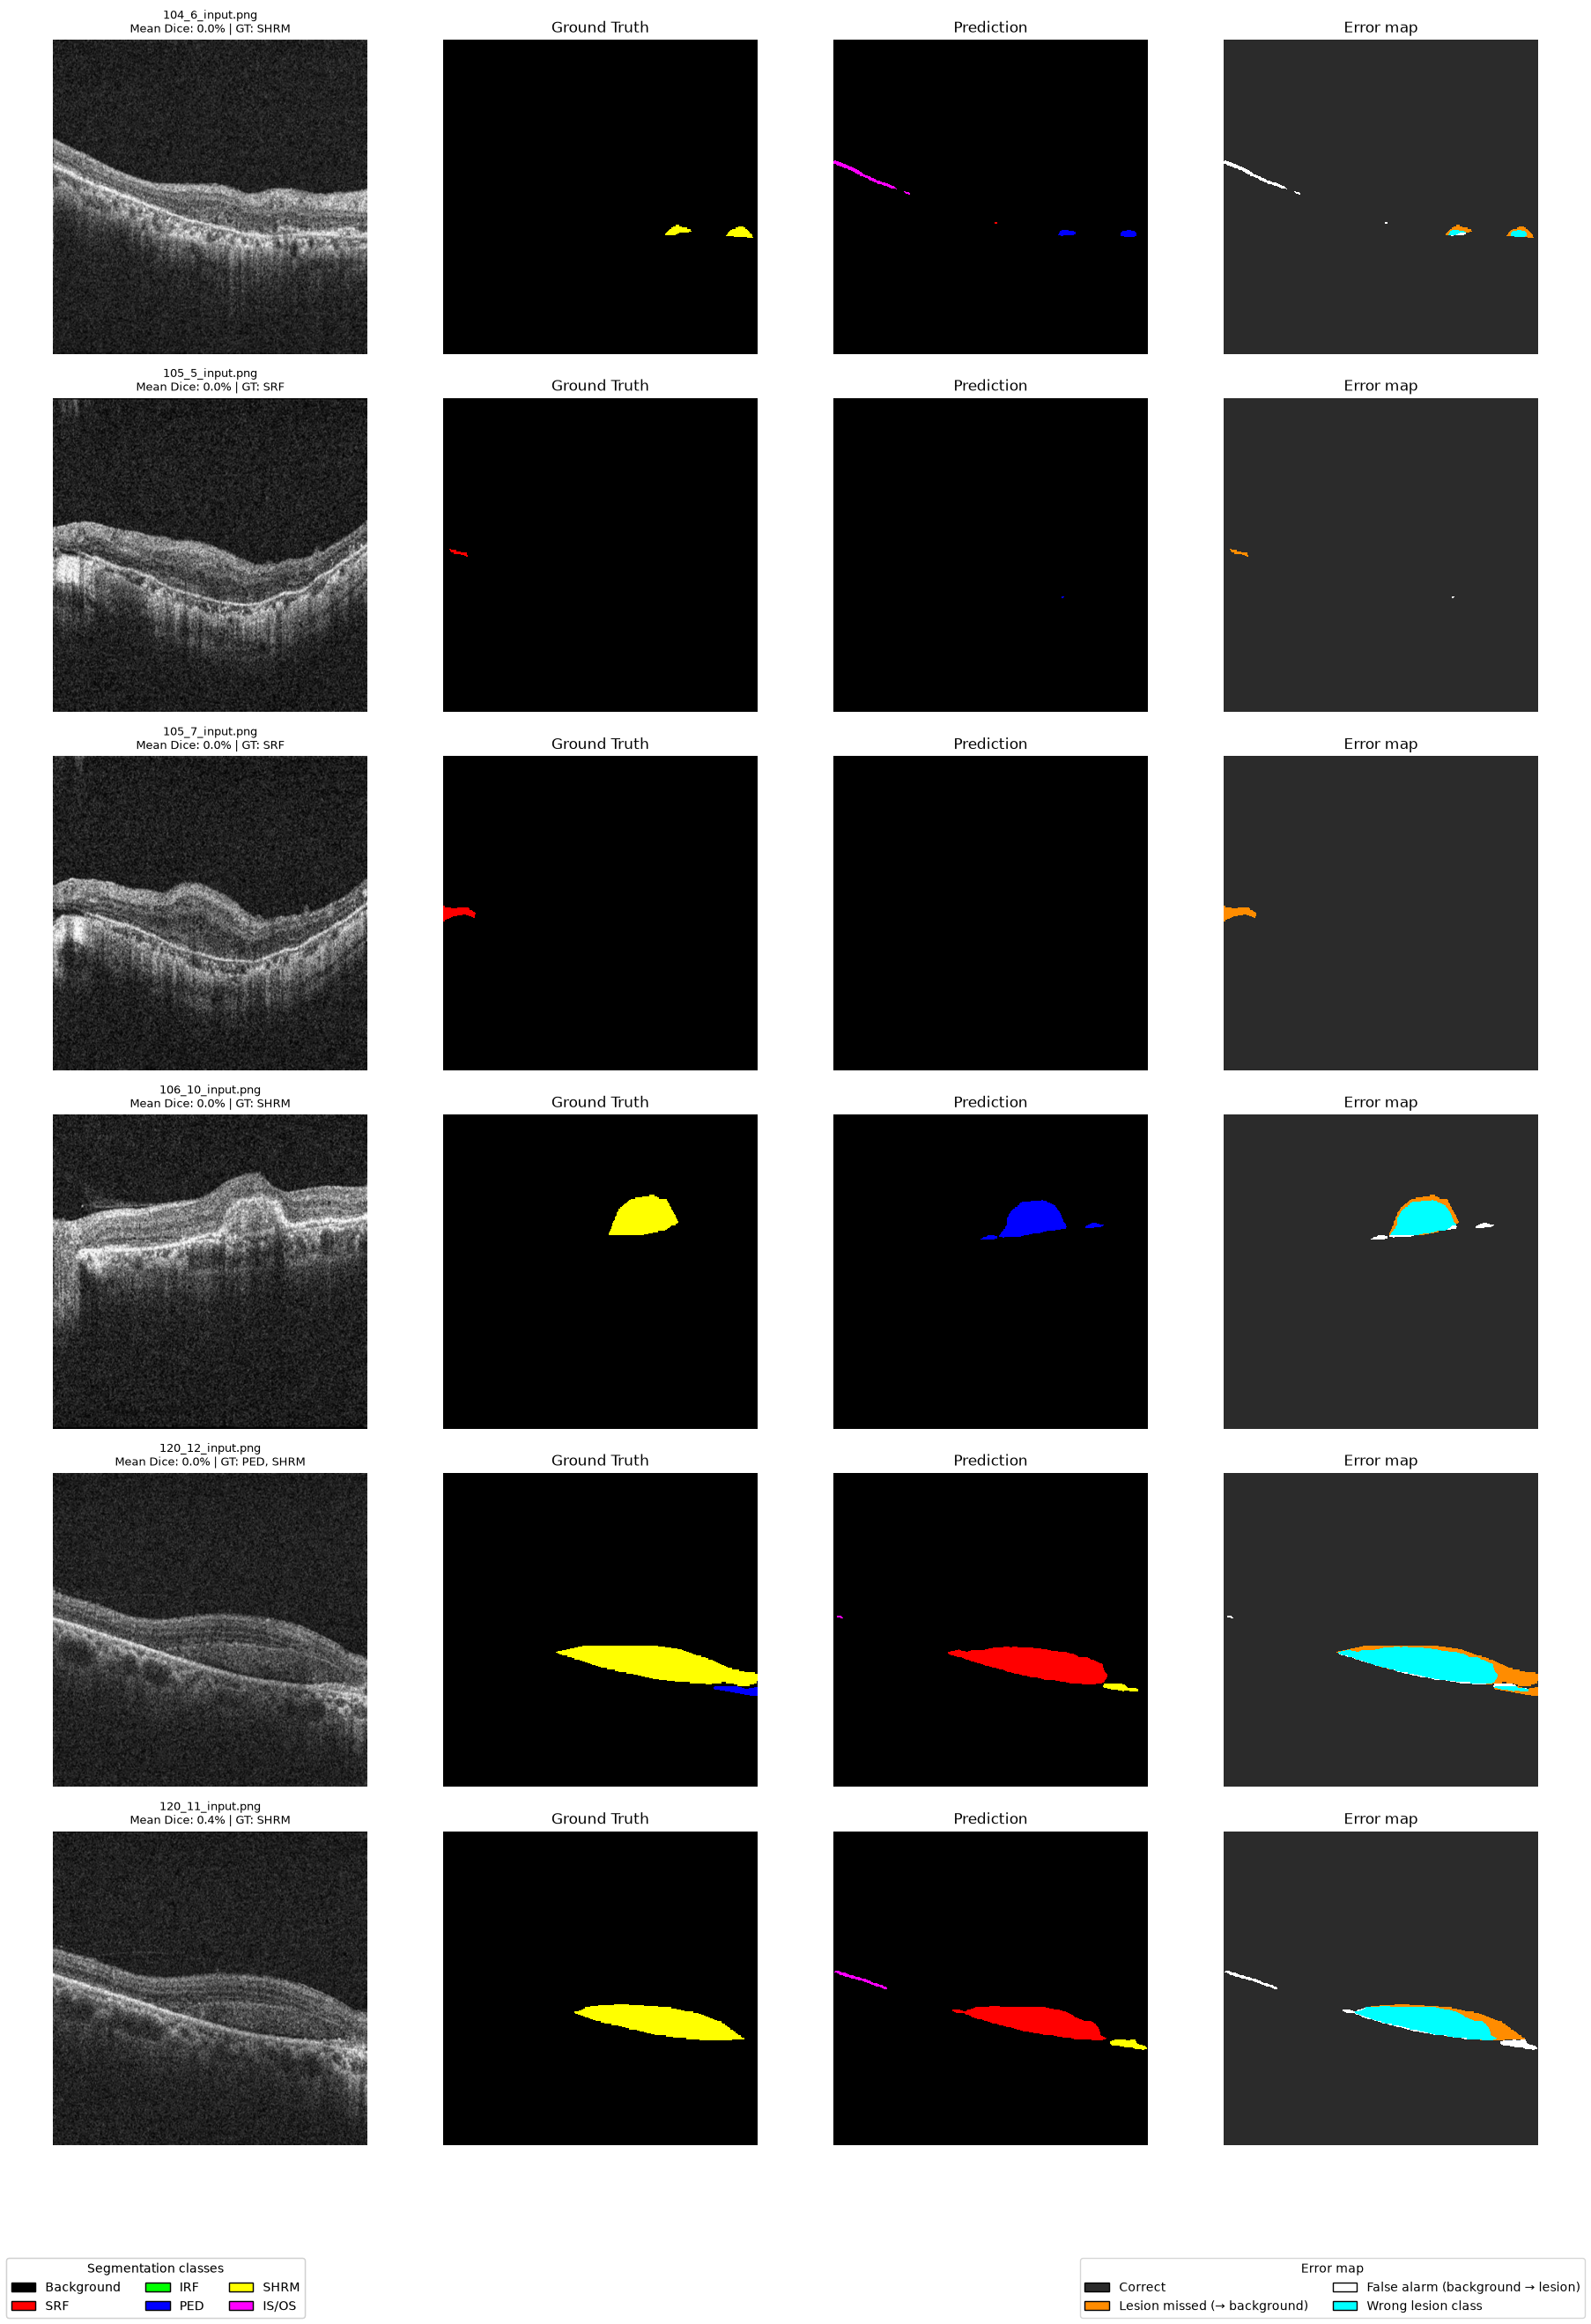


Spearman correlation of Mean Dice with candidate explanatory variables (val, scored slices only):
log10(GT lesion area in px)    0.094
# lesion classes in GT        -0.198
image mean intensity          -0.087
image contrast (std)          -0.097


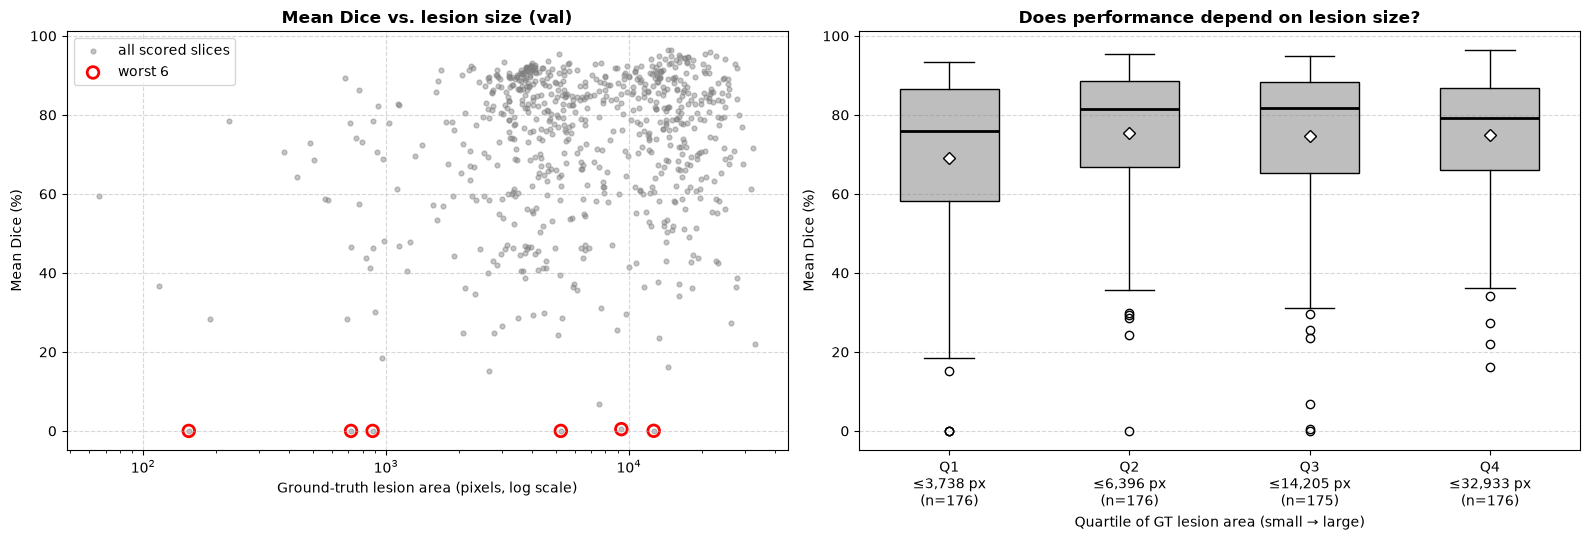

In [14]:
ERR_NAMES  = ["Correct", "Lesion missed (→ background)", "False alarm (background → lesion)", "Wrong lesion class"]
ERR_COLORS = ["#2b2b2b", "#ff8c00", "#ffffff", "#00ffff"]
ERR_CMAP = ListedColormap(ERR_COLORS)


def error_map(gt, pred):
    err = np.zeros_like(gt)
    err[(gt > 0) & (pred == 0)] = 1
    err[(gt == 0) & (pred > 0)] = 2
    err[(gt > 0) & (pred > 0) & (gt != pred)] = 3
    return err


def analyze_low_performers(split="val", k=6, focus_class=None, max_images=None):
    assert split in ("train", "val"), "Error analysis should use TRAIN or VAL data, not the test set."
    cms, meta = get_per_image_cms(MODEL_KEY, lambda: TransUNetDualHead(pretrained=False, img_size=IMG_SIZE),
                                  CKPT_PATH, lambda out: out[0], split, max_images=max_images)
    dfm = per_image_metrics(cms, "gt_present")
    score_col = "Mean_DSC" if focus_class is None else f"{focus_class}_DSC"

    gt_px, pred_px = cms.sum(axis=2), cms.sum(axis=1)       # (N, 6): GT pixels / predicted pixels per class
    info = meta.copy()
    info["score"] = dfm[score_col].to_numpy()
    info["Mean_IoU"] = dfm["Mean_IoU"].to_numpy()
    info["GT_lesion_px"] = gt_px[:, 1:].sum(axis=1)
    info["Pred_lesion_px"] = pred_px[:, 1:].sum(axis=1)
    info["n_GT_classes"] = (gt_px[:, 1:] > 0).sum(axis=1)
    info["GT_classes"] = [", ".join(n for n, c in zip(LESION_NAMES, range(1, 6)) if gt_px[i, c] > 0) or "-" for i in range(len(info))]
    info["log10_GT_px"] = np.log10(info["GT_lesion_px"] + 1)
    elig = info[info["score"].notna()].copy()
    worst = elig.nsmallest(k, "score")

    label = "Mean Dice" if focus_class is None else f"{focus_class} Dice"
    print(f"[{split}] {len(elig)}/{len(info)} slices have the scored class(es) present in the ground truth.")
    print(f"\nWorst {len(worst)} slices by {label}:")
    show = worst[["dataset_idx", "filename", "GT_classes", "GT_lesion_px", "Pred_lesion_px", "score", "Mean_IoU", "img_mean", "img_std"]].copy()
    show["Pred/GT area"] = (show["Pred_lesion_px"] / show["GT_lesion_px"].clip(lower=1)).round(2)
    show = show.rename(columns={"score": label + " (%)", "Mean_IoU": "Mean IoU (%)"}).round(2)
    print(show.to_string(index=False))

    # ---------------- Visual inspection of the worst slices ----------------
    ds = AMDDatasetModel4(DATA_DIR, split=split, target_size=(IMG_SIZE, IMG_SIZE), augment=False)
    net = load_model4(CKPT_PATH)
    rows = list(worst.itertuples())
    fig, axs = plt.subplots(len(rows), 4, figsize=(18, 4.4 * len(rows)), squeeze=False)
    for r, row in enumerate(rows):
        img, gt, _ = ds[int(row.dataset_idx)]
        with torch.no_grad():
            pred = net(img.unsqueeze(0).to(device))[0].argmax(dim=1)[0].cpu().numpy()
        gt_np = gt.numpy()
        axs[r, 0].imshow(img[0].numpy(), cmap="gray"); axs[r, 0].axis("off")
        axs[r, 0].set_title(f"{row.filename}\n{label}: {row.score:.1f}% | GT: {row.GT_classes}", fontsize=9)
        show_seg(axs[r, 1], gt_np, "Ground Truth")
        show_seg(axs[r, 2], pred, "Prediction")
        axs[r, 3].imshow(error_map(gt_np, pred), cmap=ERR_CMAP, vmin=0, vmax=3, interpolation="nearest")
        axs[r, 3].set_title("Error map"); axs[r, 3].axis("off")
    leg1 = fig.legend(handles=seg_legend_handles(), loc="lower left", ncol=3, title="Segmentation classes", frameon=True)
    fig.add_artist(leg1)
    fig.legend(handles=[Patch(facecolor=c, edgecolor="black", label=n) for c, n in zip(ERR_COLORS, ERR_NAMES)],
               loc="lower right", ncol=2, title="Error map", frameon=True)
    plt.tight_layout(rect=[0, 0.07, 1, 1])
    plt.savefig(f"{SAVE_PREFIX}_{split}_worst_examples.png", dpi=200)
    plt.show()
    del net
    cleanup_memory()

    # ---------------- Hypothesis checks ----------------
    corr = elig[["score", "log10_GT_px", "n_GT_classes", "img_mean", "img_std"]].corr(method="spearman")["score"].drop("score")
    print(f"\nSpearman correlation of {label} with candidate explanatory variables ({split}, scored slices only):")
    print(corr.rename({"log10_GT_px": "log10(GT lesion area in px)", "n_GT_classes": "# lesion classes in GT",
                       "img_mean": "image mean intensity", "img_std": "image contrast (std)"}).round(3).to_string())

    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
    axes[0].scatter(elig["GT_lesion_px"] + 1, elig["score"], s=12, color="#7f7f7f", alpha=0.45, label="all scored slices")
    axes[0].scatter(worst["GT_lesion_px"] + 1, worst["score"], s=70, facecolors="none", edgecolors="red", linewidths=2, label=f"worst {len(worst)}")
    axes[0].set_xscale("log")
    axes[0].set_xlabel("Ground-truth lesion area (pixels, log scale)"); axes[0].set_ylabel(f"{label} (%)")
    axes[0].set_title(f"{label} vs. lesion size ({split})", fontweight="bold")
    axes[0].grid(True, linestyle="--", alpha=0.5); axes[0].legend()

    bins = pd.qcut(elig["GT_lesion_px"], q=4, duplicates="drop")
    groups = [elig.loc[bins == b, "score"].to_numpy() for b in bins.cat.categories]
    bp = axes[1].boxplot(groups, patch_artist=True, showmeans=True, widths=0.55,
                         meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"},
                         medianprops={"color": "black", "linewidth": 2})
    for patch in bp["boxes"]:
        patch.set_facecolor(to_rgba("#7f7f7f", 0.5)); patch.set_edgecolor("black")
    axes[1].set_xticklabels([f"Q{i + 1}\n≤{int(b.right):,} px\n(n={len(g)})" for i, (b, g) in enumerate(zip(bins.cat.categories, groups))])
    axes[1].set_xlabel("Quartile of GT lesion area (small → large)"); axes[1].set_ylabel(f"{label} (%)")
    axes[1].set_title("Does performance depend on lesion size?", fontweight="bold")
    axes[1].grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.savefig(f"{SAVE_PREFIX}_{split}_lowdice_diagnostics.png", dpi=200)
    plt.show()
    return info

# Validation slices (default). Examples of other uses:
#   analyze_low_performers(split="train", k=6, max_images=800)    # same analysis on a random training subset
#   analyze_low_performers(split="val", k=6, focus_class="SHRM")  # worst slices for one specific class
lowdice_info = analyze_low_performers(split="val", k=6)

In [16]:
import torch
import numpy as np
import matplotlib.pyplot as plt

def evaluate_and_find_best_worst(model, val_loader, device, num_samples=3):
    model.eval()
    slice_records = []

    with torch.no_grad():
        for batch_idx, (images, masks) in enumerate(val_loader):
            images, masks = images.to(device), masks.to(device)

            # Forward pass
            outputs, _ = model(images)  # Multi-class output logits
            preds = torch.argmax(outputs, dim=1)

            # Compute metric per slice in the batch
            for i in range(images.size(0)):
                img = images[i].cpu()
                gt = masks[i].cpu()
                pred = preds[i].cpu()

                # Calculate multi-class Dice score for non-background classes (1..5)
                dice_scores = []
                for c in range(1, 6):
                    intersection = ((pred == c) & (gt == c)).sum().item()
                    cardinality = (pred == c).sum().item() + (gt == c).sum().item()
                    if cardinality > 0:
                        dice_scores.append((2.0 * intersection) / cardinality)

                # Average Dice across present classes (or 0 if no lesions are present)
                avg_dice = np.mean(dice_scores) if len(dice_scores) > 0 else 0.0

                slice_records.append({
                    'image': img.numpy().squeeze(),
                    'gt': gt.numpy(),
                    'pred': pred.numpy(),
                    'dice': avg_dice,
                    'batch_idx': batch_idx,
                    'sample_idx': i
                })

    # Sort slices by Dice score (ascending)
    slice_records.sort(key=lambda x: x['dice'])

    # Extract worst (lowest Dice) and best (highest Dice)
    worst_slices = slice_records[:num_samples]
    best_slices = slice_records[-num_samples:][::-1]  # Highest scores first

    return best_slices, worst_slices